# Vehicle Re-ID: OSNet on VRIC + VeRi-776

Runs on **Google Colab (T4 GPU)**, e.g. via the Colab VS Code extension. Datasets live on Google Drive, not in this repo.

**Just hit Run All.** Old exploratory cells are disabled (commented out, outputs kept). Run All does:
install → mount Drive → CONFIG → build the 300-ID training subsets → **Research v2** (both datasets).

Expensive work is cached on Drive under `logs/research_v2/`. After a disconnect, hit Run All again and finished work is skipped.

# Installation

In [64]:
import os

if not os.path.exists('/content/deep-person-reid'):
    !git clone https://github.com/KaiyangZhou/deep-person-reid.git

%cd /content/deep-person-reid
!pip install -q -r requirements.txt
!pip install -q chardet
!python setup.py develop --quiet

/content/deep-person-reid
/content/deep-person-reid/torchreid/metrics/rank.py:11: UserWarning: Cython evaluation (very fast so highly recommended) is unavailable, now use python evaluation.
  warnings.warn(
I0000 00:00:1794176772.638430   44166 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Traceback (most recent call last):
  File "/content/deep-person-reid/setup.py", line 47, in <module>
    version=find_version(),
            ~~~~~~~~~~~~^^
  File "/content/deep-person-reid/setup.py", line 18, in find_version
    return locals()['__version__']
           ~~~~~~~~^^^^^^^^^^^^^^^
KeyError: '__version__'


In [65]:
import sys
sys.path.insert(0, '/content/deep-person-reid')
import torchreid
print(f"torchreid version: {torchreid.__version__}")
import torch
print(f"torch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

torchreid version: 1.4.0
torch version: 2.14.1+cu130
CUDA available: True


In [66]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [67]:
# ===== CONFIG: edit paths here only =====
DRIVE_BASE = '/content/drive/MyDrive/Colab Schoolwork/CAHSI 2026'   # project folder on Google Drive
DATA_BASE  = f'{DRIVE_BASE}/Data'   # contains VRIC/ and VeRi/
LOG_BASE   = f'{DRIVE_BASE}/logs'   # checkpoints + logs persist here across disconnects
WORK       = '/content'             # fast local scratch on the Colab VM (symlinked subsets)

import os
for d in [f'{DATA_BASE}/VRIC', f'{DATA_BASE}/VeRi']:
    print(('OK      ' if os.path.isdir(d) else 'MISSING ') + d)

# Google Drive's mount sometimes returns an INCOMPLETE listing of huge folders on first access.
# listdir_retry re-lists until the expected number of files is visible.
import time
VERI_COUNTS = {'image_train': 37778, 'image_query': 1678, 'image_test': 11579}
def listdir_retry(path, expected, tries=10):
    for t in range(tries):
        names = [n for n in os.listdir(path) if n.endswith('.jpg')]
        if len(names) >= expected:
            return names
        print(f'  Drive listing of {path} incomplete ({len(names)}/{expected}), retrying...')
        time.sleep(5)
    raise RuntimeError(f'{path}: only {len(names)} of {expected} images visible on Drive after {tries} tries. Re-run this cell.')


OK      /content/drive/MyDrive/Colab Schoolwork/CAHSI 2026/Data/VRIC
OK      /content/drive/MyDrive/Colab Schoolwork/CAHSI 2026/Data/VeRi


# Model Classes

In [68]:
import os.path as osp
from torchreid.data import ImageDataset

class VRICDataset(ImageDataset):
    dataset_dir = 'vric_subset'

    def __init__(self, root='', **kwargs):
        dataset_root = osp.abspath(osp.join(root, self.dataset_dir))

        train_dir   = osp.join(dataset_root, 'train_images')
        probe_dir   = osp.join(dataset_root, 'probe_images')
        gallery_dir = osp.join(dataset_root, 'gallery_images')

        train_ann   = osp.join(dataset_root, 'vric_train.txt')
        probe_ann   = osp.join(dataset_root, 'vric_probe.txt')
        gallery_ann = osp.join(dataset_root, 'vric_gallery.txt')

        def read_ann(ann_file):
            data = []
            with open(ann_file, 'r') as f:
                for line in f:
                    line = line.strip()
                    if not line:
                        continue
                    img_name, pid, cam = line.split()
                    data.append((img_name, int(pid), int(cam)))
            return data

        train_raw   = read_ann(train_ann)
        probe_raw   = read_ann(probe_ann)
        gallery_raw = read_ann(gallery_ann)

        # remap pids and camids from training set only
        train_pids = sorted(set(pid for _, pid, _ in train_raw))
        all_cams   = sorted(set(cam for _, _, cam in train_raw + probe_raw + gallery_raw))

        pid_map = {pid: idx for idx, pid in enumerate(train_pids)}
        cam_map = {cam: idx for idx, cam in enumerate(all_cams)}

        # test pids get their own mapping independently
        test_pids = sorted(set(pid for _, pid, _ in probe_raw + gallery_raw))
        test_pid_map = {pid: idx for idx, pid in enumerate(test_pids)}

        def build_split(raw, img_dir, pid_mapping):
            data = []
            for img_name, pid, cam in raw:
                img_path = osp.join(img_dir, img_name)
                data.append((img_path, pid_mapping[pid], cam_map[cam]))
            return data

        train   = build_split(train_raw,   train_dir,   pid_map)
        query   = build_split(probe_raw,   probe_dir,   test_pid_map)
        gallery = build_split(gallery_raw, gallery_dir, test_pid_map)

        super().__init__(train, query, gallery, **kwargs)

In [69]:
import re
import glob

class VeRiDataset(ImageDataset):
    dataset_dir = 'veri_subset'

    def __init__(self, root='', **kwargs):
        dataset_dir = osp.abspath(osp.join(root, self.dataset_dir))

        train_dir   = osp.join(dataset_dir, 'image_train')
        query_dir   = osp.join(dataset_dir, 'image_query')
        gallery_dir = osp.join(dataset_dir, 'image_test')

        train   = self.process_dir(train_dir,   is_train=True)
        query   = self.process_dir(query_dir,   is_train=False)
        gallery = self.process_dir(gallery_dir, is_train=False)

        super().__init__(train, query, gallery, **kwargs)

    def process_dir(self, dir_path, is_train=True):
        img_paths = glob.glob(osp.join(dir_path, '*.jpg'))
        pattern = re.compile(r'([\d]+)_c(\d+)')
        data = []
        for img_path in img_paths:
            match = pattern.search(osp.basename(img_path))
            if not match:
                continue
            pid, camid = int(match.group(1)), int(match.group(2))
            if pid == -1:
                continue
            camid -= 1
            data.append((img_path, pid, camid))

        # remap pids to 0-based if training
        if is_train:
            pids = sorted(set(p for _, p, _ in data))
            pid_map = {p: i for i, p in enumerate(pids)}
            data = [(img, pid_map[pid], cam) for img, pid, cam in data]

        return data

# Subseting dataset

In [70]:
import random

def subset_dataset(ann_file, n, seed=42):
    with open(ann_file, 'r') as f:
        lines = [l.strip() for l in f if l.strip()]
    random.seed(seed)
    # sample by identity, not by image
    pid_to_lines = {}
    for line in lines:
        pid = line.split()[1]
        pid_to_lines.setdefault(pid, []).append(line)
    pids = list(pid_to_lines.keys())
    sampled_pids = random.sample(pids, min(n, len(pids)))
    sampled_lines = []
    for pid in sampled_pids:
        sampled_lines.extend(pid_to_lines[pid])
    return sampled_lines

In [71]:
import os
import shutil

# Remove the directory if it exists to ensure a clean state for symlinks
if os.path.exists('/content/vric_subset'):
    shutil.rmtree('/content/vric_subset')
os.makedirs('/content/vric_subset', exist_ok=True)

train_lines = subset_dataset(
    f'{DATA_BASE}/VRIC/vric_train.txt',
    n=300  # number of identities
)
probe_lines = subset_dataset(f'{DATA_BASE}/VRIC/vric_probe.txt', n=100)
# gallery must contain the SAME identities as the probe set
probe_pids = {l.split()[1] for l in probe_lines}
with open(f'{DATA_BASE}/VRIC/vric_gallery.txt') as f:
    gallery_lines = [l.strip() for l in f if l.strip() and l.split()[1] in probe_pids]

with open('/content/vric_subset/vric_train.txt', 'w') as f:
    f.write('\n'.join(train_lines))
with open('/content/vric_subset/vric_probe.txt', 'w') as f:
    f.write('\n'.join(probe_lines))
with open('/content/vric_subset/vric_gallery.txt', 'w') as f:
    f.write('\n'.join(gallery_lines))

# symlink images so dataset class can find them
os.symlink(f'{DATA_BASE}/VRIC/train_images', '/content/vric_subset/train_images')
os.symlink(f'{DATA_BASE}/VRIC/probe_images', '/content/vric_subset/probe_images')
os.symlink(f'{DATA_BASE}/VRIC/gallery_images', '/content/vric_subset/gallery_images')

# Loading data managers

In [72]:
# [DISABLED for Run All: not needed by Research v2. Remove the leading "# " to use again]
# try:
#     torchreid.data.register_image_dataset('vric_subset', VRICDataset)
# except Exception as e:
#     print(e)

# datamanager = torchreid.data.ImageDataManager(
#     root='/content',
#     sources='vric_subset',
#     height=128,
#     width=256,
#     batch_size_train=32,
#     batch_size_test=100,
#     transforms=['random_flip', 'color_jitter']
# )

In [73]:
# [DISABLED for Run All: not needed by Research v2. Remove the leading "# " to use again]
# print(datamanager.num_train_pids)

# train_data = datamanager.train_loader.dataset.data
# pids = [item[1] for item in train_data]
# print(f"max pid in train: {max(pids)}")
# print(f"min pid in train: {min(pids)}")
# print(f"unique pids in train: {len(set(pids))}")

# # see how many values are in a tuple
# print(f"tuple length: {len(train_data[0])}")
# print(f"sample tuple: {train_data[0]}")

In [74]:
import random, glob, os, re, shutil

random.seed(42)
pattern = re.compile(r'([\d]+)_c(\d+)')

def get_pids(split_dir):
    pids = set()
    for p in listdir_retry(split_dir, VERI_COUNTS[os.path.basename(split_dir)]):
        m = pattern.search(p)
        if m: pids.add(m.group(1))
    return pids

BASE = f'{DATA_BASE}/VeRi'

train_pids   = get_pids(f'{BASE}/image_train')
query_pids   = get_pids(f'{BASE}/image_query')
test_pids    = get_pids(f'{BASE}/image_test')

# sample independently — these sets are disjoint by VeRi design
sampled_train = set(random.sample(sorted(train_pids), 300))
# query/test share the same pids — sample from query, apply to both
shared_test_pids = query_pids & test_pids
sampled_test  = set(random.sample(sorted(shared_test_pids), min(100, len(shared_test_pids))))

print(f"train pids: {len(sampled_train)}, test pids: {len(sampled_test)}")
print(f"overlap between train and test: {len(sampled_train & sampled_test)}")  # should be 0

if os.path.exists('/content/veri_subset'):
    shutil.rmtree('/content/veri_subset')

split_pid_map = {
    'image_train': sampled_train,
    'image_query': sampled_test,
    'image_test':  sampled_test,
}

for split, pids in split_pid_map.items():
    os.makedirs(f'/content/veri_subset/{split}', exist_ok=True)
    src_dir = f'{BASE}/{split}'
    for img_path in (os.path.join(src_dir, n) for n in listdir_retry(src_dir, VERI_COUNTS[split])):
        m = pattern.search(os.path.basename(img_path))
        if not m: continue
        if m.group(1) in pids:
            dst = f'/content/veri_subset/{split}/{os.path.basename(img_path)}'
            if not os.path.exists(dst):
                os.symlink(img_path, dst)

for split in ['image_train', 'image_query', 'image_test']:
    print(f"{split}: {len(glob.glob(f'/content/veri_subset/{split}/*.jpg'))} images")

train pids: 300, test pids: 100
overlap between train and test: 0
image_train: 19058 images
image_query: 806 images
image_test: 5788 images


In [75]:
import os
d = f'{DATA_BASE}/VeRi'
print('VeRi folder:', sorted(os.listdir(d)) if os.path.isdir(d) else 'MISSING')
for s in ['image_train', 'image_query', 'image_test']:
    p = f'{d}/{s}'
    fs = os.listdir(p) if os.path.isdir(p) else None
    print(f'{s:12s}', 'MISSING' if fs is None else f'{len(fs)} files, e.g. {fs[:2]}')


VeRi folder: ['ReadMe.txt', 'YongtaiPoint_Google.jpg', 'camera_Dist.txt', 'camera_ID.txt', 'gt_index.txt', 'image_query', 'image_test', 'image_train', 'jk_index.txt', 'list_color.txt', 'list_type.txt', 'name_query.txt', 'name_test.txt', 'name_train.txt', 'test_label.xml', 'test_track.txt', 'test_track_VeRi.txt', 'train_label.xml']


image_train  37778 files, e.g. ['0746_c009_00034745_0.jpg', '0746_c009_00034740_0.jpg']
image_query  1678 files, e.g. ['0300_c015_00076860_0.jpg', '0300_c001_00080740_0.jpg']
image_test   11579 files, e.g. ['0677_c010_00084510_0.jpg', '0677_c010_00045035_0.jpg']


In [76]:
# [DISABLED for Run All: not needed by Research v2. Remove the leading "# " to use again]
# try:
#     torchreid.data.register_image_dataset('veri_subset', VeRiDataset)
# except Exception as e:
#     print(e)

# datamanager_veri = torchreid.data.ImageDataManager(
#     root='/content',
#     sources='veri_subset',
#     height=128,
#     width=256,
#     batch_size_train=32,
#     batch_size_test=100,
#     transforms=['random_flip', 'color_jitter']
# )

In [77]:
# [DISABLED for Run All: not needed by Research v2. Remove the leading "# " to use again]
# print(datamanager_veri.num_train_pids)

# train_data = datamanager_veri.train_loader.dataset.data
# pids = [item[1] for item in train_data]
# print(f"max pid in train: {max(pids)}")
# print(f"min pid in train: {min(pids)}")
# print(f"unique pids in train: {len(set(pids))}")

# # see how many values are in a tuple
# print(f"tuple length: {len(train_data[0])}")
# print(f"sample tuple: {train_data[0]}")

# Training Vric dataset

In [78]:
# [DISABLED for Run All: not needed by Research v2. Remove the leading "# " to use again]
# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# os.makedirs('log/osnet_x1_0', exist_ok=True)
# model = torchreid.models.build_model(
#     name='osnet_x1_0',
#     num_classes=datamanager.num_train_pids,
#     loss='softmax'
# )
# model = model.to(device)
# optimizer = torchreid.optim.build_optimizer(
#     model, optim='adam', lr=0.0003
# )
# scheduler = torchreid.optim.build_lr_scheduler(
#     optimizer, lr_scheduler='single_step', stepsize=20
# )

# engine = torchreid.engine.ImageSoftmaxEngine(
#     datamanager, model, optimizer=optimizer, scheduler=scheduler
# )
# print(device)

### Training Loop

In [79]:
# engine.run(
#     save_dir=f'{LOG_BASE}/osnet_vric',
#     max_epoch=5,
#     eval_freq=5,
#     print_freq=200,
#     test_only=False
# )

# Training Veri Dataset

In [80]:
# [DISABLED for Run All: not needed by Research v2. Remove the leading "# " to use again]
# os.makedirs('log/osnet_veri', exist_ok=True)

# model_veri = torchreid.models.build_model(
#     name='osnet_x1_0',
#     num_classes=datamanager_veri.num_train_pids,
#     loss='softmax'
# )
# model_veri = model_veri.to(device)

# optimizer_veri = torchreid.optim.build_optimizer(
#     model_veri, optim='adam', lr=0.0003
# )
# scheduler_veri = torchreid.optim.build_lr_scheduler(
#     optimizer_veri, lr_scheduler='single_step', stepsize=20
# )

# engine_veri = torchreid.engine.ImageSoftmaxEngine(
#     datamanager_veri, model_veri, optimizer=optimizer_veri, scheduler=scheduler_veri
# )

### Training Loop

In [81]:
# engine_veri.run(
#     save_dir=f'{LOG_BASE}/osnet_veri',
#     max_epoch=5,
#     eval_freq=5,
#     print_freq=200,
#     test_only=False
# )

In [82]:
# [DISABLED for Run All: not needed by Research v2. Remove the leading "# " to use again]
# checkpoint_path = f'{LOG_BASE}/osnet_vric/model/model.pth.tar-5'
# map_location = None if torch.cuda.is_available() else 'cpu'

# # Load the checkpoint explicitly with weights_only=False
# checkpoint = torch.load(checkpoint_path, map_location=map_location, weights_only=False)

# # Extract the state_dict
# state_dict = checkpoint['state_dict']

# # Remove 'module.' prefix if the model was saved with DataParallel
# new_state_dict = {}
# for k, v in state_dict.items():
#     if k.startswith('module.'):
#         new_state_dict[k[7:]] = v
#     else:
#         new_state_dict[k] = v
# state_dict = new_state_dict

# # Load the state_dict into the model
# model.load_state_dict(state_dict)

# print(f"Successfully loaded pretrained weights from {checkpoint_path}")

# Stratifying By flaw

In [83]:
# [DISABLED for Run All: not needed by Research v2. Remove the leading "# " to use again]
# import cv2
# import numpy as np
# import os

# def compute_blur_score(img_path):
#     img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
#     if img is None:
#         return None
#     return cv2.Laplacian(img, cv2.CV_64F).var()

# def compute_resolution_score(img_path):
#     img = cv2.imread(img_path)
#     if img is None:
#         return None
#     h, w = img.shape[:2]
#     return h * w  # total pixels as proxy for resolution

# def score_split(ann_file, img_dir):
#     scores = []
#     with open(ann_file, 'r') as f:
#         for line in f:
#             line = line.strip()
#             if not line:
#                 continue
#             img_name, pid, cam = line.split()
#             img_path = os.path.join(img_dir, img_name)
#             if not os.path.exists(img_path):
#                 continue
#             blur  = compute_blur_score(img_path)
#             res   = compute_resolution_score(img_path)
#             scores.append({
#                 'img_name': img_name,
#                 'pid': int(pid),
#                 'cam': int(cam),
#                 'blur_score': blur,
#                 'resolution': res
#             })
#     return scores

In [84]:
# [DISABLED for Run All: not needed by Research v2. Remove the leading "# " to use again]
# probe_dir = f'{DATA_BASE}/VRIC/probe_images'
# gallery_dir = f'{DATA_BASE}/VRIC/gallery_images'
# probe_ann = f'{DATA_BASE}/VRIC/vric_probe.txt'
# gallery_ann = f'{DATA_BASE}/VRIC/vric_gallery.txt'

# probe_scores = score_split(probe_ann, probe_dir)
# gallery_scores = score_split(gallery_ann, gallery_dir)

# print(f"Scored {len(probe_scores)} probe images")
# print(f"Scored {len(gallery_scores)} gallery images")

In [85]:
# [DISABLED for Run All: not needed by Research v2. Remove the leading "# " to use again]
# import pandas as pd

# probe_df   = pd.DataFrame(probe_scores)
# gallery_df = pd.DataFrame(gallery_scores)

# # low blur score = blurry, high blur score = sharp
# blur_threshold = probe_df['blur_score'].median()
# res_threshold  = probe_df['resolution'].median()

# print(f"Blur threshold (median): {blur_threshold:.2f}")
# print(f"Resolution threshold (median): {res_threshold:.0f}")

# # split probe into groups
# probe_blurry  = probe_df[probe_df['blur_score'] <  blur_threshold]
# probe_sharp   = probe_df[probe_df['blur_score'] >= blur_threshold]
# probe_low_res = probe_df[probe_df['resolution'] <  res_threshold]
# probe_high_res= probe_df[probe_df['resolution'] >= res_threshold]

# print(f"\nBlurry probe images:   {len(probe_blurry)}")
# print(f"Sharp probe images:    {len(probe_sharp)}")
# print(f"Low-res probe images:  {len(probe_low_res)}")
# print(f"High-res probe images: {len(probe_high_res)}")


In [86]:
# [DISABLED for Run All: not needed by Research v2. Remove the leading "# " to use again]
# from PIL import Image
# import os

# PROBE_DIR = f'{DATA_BASE}/VRIC/probe_images'

# most_blurry   = probe_df.loc[probe_df['blur_score'].idxmin()]
# most_sharp    = probe_df.loc[probe_df['blur_score'].idxmax()]
# most_low_res  = probe_df.loc[probe_df['resolution'].idxmin()]
# most_high_res = probe_df.loc[probe_df['resolution'].idxmax()]

# samples = [
#     (most_blurry,   'most_blurry'),
#     (most_sharp,    'most_sharp'),
#     (most_low_res,  'most_low_res'),
#     (most_high_res, 'most_high_res'),
# ]

# save_dir = f'{DRIVE_BASE}/probe_samples'
# os.makedirs(save_dir, exist_ok=True)

# for row, name in samples:
#     img = Image.open(f'{PROBE_DIR}/{row["img_name"]}')
#     img.save(f'{save_dir}/{name}.jpg')
#     print(f"Saved {name} — blur: {row['blur_score']:.1f}, res: {row['resolution']:.0f}px")

In [87]:
# [DISABLED for Run All: not needed by Research v2. Remove the leading "# " to use again]
# os.makedirs('/content/vric_stratified', exist_ok=True)

# # symlink images
# for split in ['probe_images', 'gallery_images', 'train_images']:
#     dst = f'/content/vric_stratified/{split}'
#     src = f'{DATA_BASE}/VRIC/{split}'
#     if not os.path.exists(dst):
#         os.symlink(src, dst)

# def write_ann(df, path):
#     with open(path, 'w') as f:
#         for _, row in df.iterrows():
#             f.write(f"{row['img_name']} {row['pid']} {row['cam']}\n")

# # copy full train and gallery annotations unchanged
# import shutil
# shutil.copy(
#     f'{DATA_BASE}/VRIC/vric_train.txt',
#     '/content/vric_stratified/vric_train.txt'
# )
# shutil.copy(
#     f'{DATA_BASE}/VRIC/vric_gallery.txt',
#     '/content/vric_stratified/vric_gallery.txt'
# )

# # write probe subsets
# write_ann(probe_blurry,   '/content/vric_stratified/probe_blurry.txt')
# write_ann(probe_sharp,    '/content/vric_stratified/probe_sharp.txt')
# write_ann(probe_low_res,  '/content/vric_stratified/probe_lowres.txt')
# write_ann(probe_high_res, '/content/vric_stratified/probe_highres.txt')

# print("Annotation files written")

In [88]:
# [DISABLED for Run All: not needed by Research v2. Remove the leading "# " to use again]
# class VRICStratifiedDataset(ImageDataset):
#     dataset_dir = 'vric_stratified'

#     def __init__(self, root='', probe_file='vric_gallery.txt', **kwargs):
#         dataset_dir = osp.abspath(osp.join(root, self.dataset_dir))

#         train_dir   = osp.join(dataset_dir, 'train_images')
#         probe_dir   = osp.join(dataset_dir, 'probe_images')
#         gallery_dir = osp.join(dataset_dir, 'gallery_images')

#         train_ann   = osp.join(dataset_dir, 'vric_train.txt')
#         probe_ann   = osp.join(dataset_dir, probe_file)
#         gallery_ann = osp.join(dataset_dir, 'vric_gallery.txt')

#         def read_ann(ann_file):
#             data = []
#             with open(ann_file, 'r') as f:
#                 for line in f:
#                     line = line.strip()
#                     if not line:
#                         continue
#                     img_name, pid, cam = line.split()
#                     data.append((img_name, int(pid), int(cam)))
#             return data

#         train_raw   = read_ann(train_ann)
#         probe_raw   = read_ann(probe_ann)
#         gallery_raw = read_ann(gallery_ann)

#         train_pids = sorted(set(pid for _, pid, _ in train_raw))
#         all_cams   = sorted(set(cam for _, _, cam in train_raw + probe_raw + gallery_raw))
#         test_pids  = sorted(set(pid for _, pid, _ in probe_raw + gallery_raw))

#         pid_map      = {pid: idx for idx, pid in enumerate(train_pids)}
#         cam_map      = {cam: idx for idx, cam in enumerate(all_cams)}
#         test_pid_map = {pid: idx for idx, pid in enumerate(test_pids)}

#         def build_split(raw, img_dir, pid_mapping):
#             data = []
#             for img_name, pid, cam in raw:
#                 img_path = osp.join(img_dir, img_name)
#                 if not osp.exists(img_path):
#                     continue
#                 data.append((img_path, pid_mapping[pid], cam_map[cam]))
#             return data

#         train   = build_split(train_raw,   train_dir,   pid_map)
#         query   = build_split(probe_raw,   probe_dir,   test_pid_map)
#         gallery = build_split(gallery_raw, gallery_dir, test_pid_map)

#         super().__init__(train, query, gallery, **kwargs)

In [89]:
# [DISABLED for Run All: not needed by Research v2. Remove the leading "# " to use again]
# results = {}

# for probe_file, label in [
#     ('probe_blurry.txt',  'blurry'),
#     ('probe_sharp.txt',   'sharp'),
#     ('probe_lowres.txt',  'low_res'),
#     ('probe_highres.txt', 'high_res'),
# ]:
#     try:
#       torchreid.data.register_image_dataset(f'vric_{label}',
#           lambda root, **kw: VRICStratifiedDataset(root, probe_file=probe_file, **kw))
#     except Exception as e:
#         print(e)


#     dm = torchreid.data.ImageDataManager(
#         root='/content',
#         sources=f'vric_{label}',
#         height=128,
#         width=256,
#         batch_size_train=32,
#         batch_size_test=100,
#     )

#     engine_eval = torchreid.engine.ImageSoftmaxEngine(
#         dm, model, optimizer=optimizer, scheduler=scheduler
#     )

#     print(f"\n=== Evaluating: {label} ===")
#     engine_eval.run(
#         save_dir=f'log/stratified_{label}',
#         max_epoch=0,
#         start_eval=True,
#         test_only=True,
#     )

In [90]:
# [DISABLED for Run All: not needed by Research v2. Remove the leading "# " to use again]
# data = {
#     "Subset": [
#         "VRIC Full baseline",
#         "Blurry queries",
#         "Sharp queries",
#         "Low-res queries",
#         "High-res queries",
#         "VeRi-776 (clean)"
#     ],
#     "Rank-1": [59.2, 31.0, 23.2, 20.7, 33.4, 90.8],
#     "Rank-5": [79.2, 54.1, 44.1, 42.7, 55.5, 95.6],
#     "mAP": [68.3, 41.8, 33.3, 31.5, 43.6, 56.6]
# }

# df = pd.DataFrame(data)
# df.head()

In [91]:
# [DISABLED for Run All: not needed by Research v2. Remove the leading "# " to use again]
# """
# K-Fold Cross Validation for Vehicle Re-ID (VRIC + VeRi)
# Drop this cell block into your existing ReIdTraining.ipynb after your
# dataset class definitions and before your single-run training cells.

# Requires: torchreid, torch, pandas, numpy, sklearn — all already in your env.
# """

# import os
# import os.path as osp
# import shutil
# import random
# import numpy as np
# import pandas as pd
# from collections import defaultdict
# from sklearn.model_selection import KFold
# import torch
# import torchreid


# # ─────────────────────────────────────────────
# # 1.  HELPERS
# # ─────────────────────────────────────────────

# def read_ann(ann_file):
#     """Returns list of (img_name, pid, cam) tuples."""
#     data = []
#     with open(ann_file, 'r') as f:
#         for line in f:
#             line = line.strip()
#             if not line:
#                 continue
#             img_name, pid, cam = line.split()
#             data.append((img_name, int(pid), int(cam)))
#     return data


# def write_ann(records, path):
#     with open(path, 'w') as f:
#         for img_name, pid, cam in records:
#             f.write(f"{img_name} {pid} {cam}\n")


# def group_by_pid(records):
#     """Returns {pid: [(img_name, pid, cam), ...]}"""
#     groups = defaultdict(list)
#     for rec in records:
#         groups[rec[1]].append(rec)
#     return groups


# def extract_metrics(engine, save_dir, datamanager, model, optimizer, scheduler):
#     """
#     Runs test_only eval and scrapes Rank-1, Rank-5, mAP from torchreid's
#     logged output by redirecting stdout temporarily.
#     Returns dict with keys rank1, rank5, mAP.
#     """
#     import io, sys
#     buf = io.StringIO()
#     old_stdout = sys.stdout
#     sys.stdout = buf

#     engine_eval = torchreid.engine.ImageSoftmaxEngine(
#         datamanager, model, optimizer=optimizer, scheduler=scheduler
#     )
#     engine_eval.run(
#         save_dir=save_dir,
#         max_epoch=0,
#         start_eval=True,
#         test_only=True,
#         print_freq=9999,
#     )

#     sys.stdout = old_stdout
#     output = buf.getvalue()
#     print(output)  # still show it in the notebook

#     metrics = {'rank1': None, 'rank5': None, 'mAP': None}
#     for line in output.splitlines():
#         # torchreid prints something like:
#         # "mAP: 68.3%  |  Rank-1: 59.2%  Rank-5: 79.2%"
#         l = line.lower()
#         if 'rank-1' in l:
#             import re
#             r1 = re.search(r'rank-1\s*[:\s]+([0-9.]+)', l)
#             r5 = re.search(r'rank-5\s*[:\s]+([0-9.]+)', l)
#             mp = re.search(r'map\s*[:\s]+([0-9.]+)', l)
#             if r1: metrics['rank1'] = float(r1.group(1))
#             if r5: metrics['rank5'] = float(r5.group(1))
#             if mp: metrics['mAP']   = float(mp.group(1))
#     return metrics


# # ─────────────────────────────────────────────
# # 2.  GENERIC K-FOLD CV RUNNER
# # ─────────────────────────────────────────────

# def run_kfold_cv(
#     dataset_name,           # 'vric' or 'veri'
#     train_ann_file,         # full path to training annotation txt
#     query_ann_file,         # full path to query/probe annotation txt
#     gallery_ann_file,       # full path to gallery annotation txt
#     train_img_dir,
#     query_img_dir,
#     gallery_img_dir,
#     drive_log_root,         # e.g. '/content/drive/MyDrive/.../logs'
#     workspace_root='/content',
#     n_splits=5,
#     max_epoch=5,
#     eval_freq=5,
#     lr=0.0003,
#     batch_size_train=32,
#     batch_size_test=100,
#     height=128,
#     width=256,
#     seed=42,
# ):
#     """
#     Performs k-fold CV over training identities.

#     For each fold:
#       - k-1 folds → train split
#       - 1 fold    → held-out; merged into gallery, its images also used as query
#         (standard re-ID closed-world evaluation on held-out IDs)
#       - Original query/gallery sets used as-is for the main eval split

#     Returns a DataFrame with per-fold and aggregated metrics.
#     """
#     random.seed(seed)
#     np.random.seed(seed)

#     train_records   = read_ann(train_ann_file)
#     query_records   = read_ann(query_ann_file)
#     gallery_records = read_ann(gallery_ann_file)

#     # group train records by identity
#     pid_groups  = group_by_pid(train_records)
#     all_pids    = np.array(sorted(pid_groups.keys()))

#     kf = KFold(n_splits=n_splits, shuffle=True, random_state=seed)

#     fold_results = []
#     device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

#     for fold_idx, (train_idx, val_idx) in enumerate(kf.split(all_pids)):
#         print(f"\n{'='*60}")
#         print(f"  {dataset_name.upper()} | FOLD {fold_idx + 1} / {n_splits}")
#         print(f"{'='*60}")

#         train_pids = all_pids[train_idx].tolist()
#         val_pids   = all_pids[val_idx].tolist()

#         # build fold annotation records
#         fold_train = [rec for pid in train_pids for rec in pid_groups[pid]]

#         # val pids become an additional query+gallery for this fold's eval
#         val_records = [rec for pid in val_pids for rec in pid_groups[pid]]
#         # use first image per val_pid as query, rest as gallery
#         val_pid_groups = group_by_pid(val_records)
#         fold_val_query   = [recs[0]  for recs in val_pid_groups.values()]
#         fold_val_gallery = [rec for recs in val_pid_groups.values() for rec in recs[1:]]

#         # combine with original eval sets
#         fold_query   = query_records   + fold_val_query
#         fold_gallery = gallery_records + fold_val_gallery

#         # ── write fold ann files ──────────────────────────────────────
#         fold_dir = f'{workspace_root}/{dataset_name}_fold_{fold_idx}'
#         if osp.exists(fold_dir):
#             shutil.rmtree(fold_dir)
#         os.makedirs(fold_dir, exist_ok=True)

#         write_ann(fold_train,   osp.join(fold_dir, 'train.txt'))
#         write_ann(fold_query,   osp.join(fold_dir, 'query.txt'))
#         write_ann(fold_gallery, osp.join(fold_dir, 'gallery.txt'))

#         # symlink image dirs (avoid copying)
#         for split_name, src in [
#             ('train_images',   train_img_dir),
#             ('query_images',   query_img_dir),
#             ('gallery_images', gallery_img_dir),
#         ]:
#             dst = osp.join(fold_dir, split_name)
#             if not osp.exists(dst):
#                 os.symlink(src, dst)

#         # ── inline dataset class for this fold ───────────────────────
#         fold_dir_captured = fold_dir  # capture for closure

#         class FoldDataset(torchreid.data.ImageDataset):
#             dataset_dir = osp.basename(fold_dir_captured)

#             def __init__(self, root='', **kwargs):
#                 _base = osp.abspath(osp.join(root, self.dataset_dir))

#                 def _read(f):
#                     out = []
#                     with open(f) as fh:
#                         for line in fh:
#                             line = line.strip()
#                             if not line: continue
#                             img, pid, cam = line.split()
#                             out.append((img, int(pid), int(cam)))
#                     return out

#                 tr_raw  = _read(osp.join(_base, 'train.txt'))
#                 qu_raw  = _read(osp.join(_base, 'query.txt'))
#                 ga_raw  = _read(osp.join(_base, 'gallery.txt'))

#                 tr_pids  = sorted(set(p for _, p, _ in tr_raw))
#                 all_cams = sorted(set(c for _, _, c in tr_raw + qu_raw + ga_raw))
#                 te_pids  = sorted(set(p for _, p, _ in qu_raw + ga_raw))

#                 pid_map      = {p: i for i, p in enumerate(tr_pids)}
#                 cam_map      = {c: i for i, c in enumerate(all_cams)}
#                 te_pid_map   = {p: i for i, p in enumerate(te_pids)}

#                 def _build(raw, img_dir, pm):
#                     out = []
#                     for img_name, pid, cam in raw:
#                         path = osp.join(_base, img_dir, img_name)
#                         if not osp.exists(path): continue
#                         out.append((path, pm[pid], cam_map[cam]))
#                     return out

#                 train   = _build(tr_raw, 'train_images',   pid_map)
#                 query   = _build(qu_raw, 'query_images',   te_pid_map)
#                 gallery = _build(ga_raw, 'gallery_images', te_pid_map)

#                 super().__init__(train, query, gallery, **kwargs)

#         fold_key = f'{dataset_name}_fold_{fold_idx}'
#         try:
#             torchreid.data.register_image_dataset(fold_key, FoldDataset)
#         except Exception:
#             pass  # already registered on re-runs

#         dm = torchreid.data.ImageDataManager(
#             root=workspace_root,
#             sources=fold_key,
#             height=height,
#             width=width,
#             batch_size_train=batch_size_train,
#             batch_size_test=batch_size_test,
#             transforms=['random_flip', 'color_jitter'],
#         )

#         # ── build fresh model + optimizer each fold ───────────────────
#         model = torchreid.models.build_model(
#             name='osnet_x1_0',
#             num_classes=dm.num_train_pids,
#             loss='softmax',
#         ).to(device)

#         optimizer = torchreid.optim.build_optimizer(model, optim='adam', lr=lr)
#         scheduler = torchreid.optim.build_lr_scheduler(
#             optimizer, lr_scheduler='single_step', stepsize=20
#         )

#         fold_save_dir = osp.join(drive_log_root, f'{dataset_name}_fold_{fold_idx}')
#         os.makedirs(fold_save_dir, exist_ok=True)

#         engine = torchreid.engine.ImageSoftmaxEngine(
#             dm, model, optimizer=optimizer, scheduler=scheduler
#         )
#         engine.run(
#             save_dir=fold_save_dir,
#             max_epoch=max_epoch,
#             eval_freq=eval_freq,
#             print_freq=200,
#             test_only=False,
#         )

#         # ── scrape final metrics from torchreid log ───────────────────
#         # torchreid logs to save_dir/log.txt; parse last rank/mAP line
#         log_path = osp.join(fold_save_dir, 'log.txt')
#         metrics  = {'rank1': None, 'rank5': None, 'mAP': None}
#         if osp.exists(log_path):
#             import re
#             with open(log_path) as lf:
#                 for line in lf:
#                     l = line.lower()
#                     if 'rank-1' in l:
#                         r1 = re.search(r'rank-1\s*[:\s]+([0-9.]+)', l)
#                         r5 = re.search(r'rank-5\s*[:\s]+([0-9.]+)', l)
#                         mp = re.search(r'map\s*[:\s]+([0-9.]+)', l)
#                         if r1: metrics['rank1'] = float(r1.group(1))
#                         if r5: metrics['rank5'] = float(r5.group(1))
#                         if mp: metrics['mAP']   = float(mp.group(1))

#         fold_results.append({
#             'fold':   fold_idx + 1,
#             'rank1':  metrics['rank1'],
#             'rank5':  metrics['rank5'],
#             'mAP':    metrics['mAP'],
#             'n_train_ids': len(train_pids),
#             'n_val_ids':   len(val_pids),
#         })
#         print(f"  Fold {fold_idx+1} → Rank-1: {metrics['rank1']}  "
#               f"Rank-5: {metrics['rank5']}  mAP: {metrics['mAP']}")

#         # free GPU memory between folds
#         del model, optimizer, scheduler, engine, dm
#         torch.cuda.empty_cache()

#     # ── aggregate ─────────────────────────────────────────────────────
#     results_df = pd.DataFrame(fold_results)
#     summary = {
#         'fold':   'mean ± std',
#         'rank1':  f"{results_df['rank1'].mean():.2f} ± {results_df['rank1'].std():.2f}",
#         'rank5':  f"{results_df['rank5'].mean():.2f} ± {results_df['rank5'].std():.2f}",
#         'mAP':    f"{results_df['mAP'].mean():.2f} ± {results_df['mAP'].std():.2f}",
#         'n_train_ids': '',
#         'n_val_ids':   '',
#     }
#     results_df = pd.concat([results_df, pd.DataFrame([summary])], ignore_index=True)
#     return results_df


# # ─────────────────────────────────────────────
# # 3.  RUN — VRIC
# # ─────────────────────────────────────────────

# # paths come from the CONFIG cell at the top

# vric_results = run_kfold_cv(
#     dataset_name      = 'vric',
#     train_ann_file    = f'{DATA_BASE}/VRIC/vric_train.txt',
#     query_ann_file    = f'{DATA_BASE}/VRIC/vric_probe.txt',
#     gallery_ann_file  = f'{DATA_BASE}/VRIC/vric_gallery.txt',
#     train_img_dir     = f'{DATA_BASE}/VRIC/train_images',
#     query_img_dir     = f'{DATA_BASE}/VRIC/probe_images',
#     gallery_img_dir   = f'{DATA_BASE}/VRIC/gallery_images',
#     drive_log_root    = f'{LOG_BASE}/kfold_vric',
#     workspace_root    = '/content',
#     n_splits          = 5,
#     max_epoch         = 5,
#     eval_freq         = 5,
#     lr                = 0.0003,
# )

# print("\nVRIC 5-Fold CV Results:")
# print(vric_results.to_string(index=False))

In [92]:
# [DISABLED for Run All: not needed by Research v2. Remove the leading "# " to use again]
# # ─────────────────────────────────────────────
# # 4.  RUN — VeRi
# # ─────────────────────────────────────────────

# import glob, re

# def veri_dir_to_ann(img_dir, out_ann_path, is_train=True):
#     pattern = re.compile(r'([\d]+)_c(\d+)')
#     records = []
#     for img_path in sorted(glob.glob(osp.join(img_dir, '*.jpg'))):
#         m = pattern.search(osp.basename(img_path))
#         if not m: continue
#         pid, cam = int(m.group(1)), int(m.group(2)) - 1
#         if pid == -1: continue
#         records.append((osp.basename(img_path), pid, cam))
#     write_ann(records, out_ann_path)
#     return records

# os.makedirs('/content/veri_ann_cache', exist_ok=True)
# veri_train_ann   = '/content/veri_ann_cache/train.txt'
# veri_query_ann   = '/content/veri_ann_cache/query.txt'
# veri_gallery_ann = '/content/veri_ann_cache/gallery.txt'

# veri_dir_to_ann(f'{DATA_BASE}/VeRi/image_train', veri_train_ann)
# veri_dir_to_ann(f'{DATA_BASE}/VeRi/image_query', veri_query_ann)
# veri_dir_to_ann(f'{DATA_BASE}/VeRi/image_test',  veri_gallery_ann)

# veri_results = run_kfold_cv(
#     dataset_name      = 'veri',
#     train_ann_file    = veri_train_ann,
#     query_ann_file    = veri_query_ann,
#     gallery_ann_file  = veri_gallery_ann,
#     train_img_dir     = f'{DATA_BASE}/VeRi/image_train',
#     query_img_dir     = f'{DATA_BASE}/VeRi/image_query',
#     gallery_img_dir   = f'{DATA_BASE}/VeRi/image_test',
#     drive_log_root    = f'{LOG_BASE}/kfold_veri',
#     workspace_root    = '/content',
#     n_splits          = 3,
#     max_epoch         = 5,
#     eval_freq         = 5,
#     lr                = 0.0003,
# )

# print("\nVeRi 3-Fold CV Results:")
# print(veri_results.to_string(index=False))

# # ─────────────────────────────────────────────
# # 5.  COMBINED SUMMARY TABLE (paper-ready)
# # ─────────────────────────────────────────────

# print("\n\n" + "="*60)
# print("  FINAL SUMMARY — CV Results (mean ± std)")
# print("="*60)
# # print("\nVRIC (5-fold):")
# # print(vric_results[vric_results['fold'] == 'mean ± std'][['rank1','rank5','mAP']].to_string(index=False))
# print("\nVeRi (3-fold):")
# print(veri_results[veri_results['fold'] == 'mean ± std'][['rank1','rank5','mAP']].to_string(index=False))

In [93]:
# [DISABLED for Run All: not needed by Research v2. Remove the leading "# " to use again]
# # rebuild datamanager with full veri query/gallery
# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# try:
#     torchreid.data.register_image_dataset('veri_subset', VeRiDataset)
# except Exception as e:
#     print(e)

# datamanager_veri = torchreid.data.ImageDataManager(
#     root='/content',
#     sources='veri_subset',
#     height=128,
#     width=256,
#     batch_size_train=32,
#     batch_size_test=100,
#     transforms=['random_flip', 'color_jitter']
# )

# # load best fold checkpoint (fold 2 had highest rank-1 = 87.2)
# veri_checkpoint = f'{LOG_BASE}/kfold_veri/veri_fold_1/model/model.pth.tar-5'
# map_location = None if torch.cuda.is_available() else 'cpu'
# checkpoint = torch.load(veri_checkpoint, map_location=map_location, weights_only=False)
# state_dict = {k.replace('module.', ''): v for k, v in checkpoint['state_dict'].items()}

# model_veri = torchreid.models.build_model(
#     name='osnet_x1_0',
#     num_classes=384,
#     loss='softmax',
# ).to(device)
# model_veri.load_state_dict(state_dict)

# optimizer_veri = torchreid.optim.build_optimizer(model_veri, optim='adam', lr=0.0003)
# scheduler_veri = torchreid.optim.build_lr_scheduler(optimizer_veri, lr_scheduler='single_step', stepsize=20)

# engine_veri = torchreid.engine.ImageSoftmaxEngine(
#     datamanager_veri, model_veri,
#     optimizer=optimizer_veri,
#     scheduler=scheduler_veri
# )
# engine_veri.run(
#     save_dir='/content/veri_baseline_eval',
#     max_epoch=0,
#     test_only=True,
# )

In [94]:
# [DISABLED for Run All: not needed by Research v2. Remove the leading "# " to use again]
# import numpy as np
# import pandas as pd

# vric_folds = [
#     {'fold': 1, 'rank1': 55.4, 'rank5': 77.4, 'mAP': 65.3},
#     {'fold': 2, 'rank1': 57.8, 'rank5': 79.0, 'mAP': 67.4},
#     {'fold': 3, 'rank1': 55.2, 'rank5': 77.1, 'mAP': 65.0},
#     {'fold': 4, 'rank1': 56.1, 'rank5': 77.9, 'mAP': 65.9},
#     {'fold': 5, 'rank1': 57.4, 'rank5': 78.3, 'mAP': 66.8},
# ]

# veri_folds = [
#     {'fold': 1, 'rank1': 85.6, 'rank5': 92.6, 'mAP': 47.6},
#     {'fold': 2, 'rank1': 87.2, 'rank5': 94.1, 'mAP': 49.5},
#     {'fold': 3, 'rank1': 86.7, 'rank5': 93.8, 'mAP': 49.3},
# ]

# for name, folds in [('VRIC 5-Fold CV', vric_folds), ('VeRi 3-Fold CV', veri_folds)]:
#     df = pd.DataFrame(folds)
#     summary = {
#         'fold':  'mean ± std',
#         'rank1': f"{df['rank1'].mean():.2f} ± {df['rank1'].std():.2f}",
#         'rank5': f"{df['rank5'].mean():.2f} ± {df['rank5'].std():.2f}",
#         'mAP':   f"{df['mAP'].mean():.2f} ± {df['mAP'].std():.2f}",
#     }
#     df = pd.concat([df, pd.DataFrame([summary])], ignore_index=True)
#     print(f"\n{name}:")
#     print(df.to_string(index=False))

In [95]:
# [DISABLED for Run All: not needed by Research v2. Remove the leading "# " to use again]
# import pandas as pd

# data = {
#     'Dataset': ['VeRi-776 Baseline', 'VRIC Full Baseline', 'VRIC Blurry Queries',
#                 'VRIC Sharp Queries', 'VRIC Low-res Queries', 'VRIC High-res Queries'],
#     'Rank-1 (%)': [91.3, 59.2, 31.0, 23.2, 20.7, 33.4],
#     'Rank-5 (%)': [95.4, 79.2, 54.1, 44.1, 42.7, 55.5],
#     'mAP (%)':   [56.5, 68.3, 41.8, 33.3, 31.5, 43.6],
# }

# results_df = pd.DataFrame(data)
# results_df

# Research v2: fair evaluation, blur vs. resolution, low-res augmentation (VRIC + VeRi-776)

Every step runs for **both datasets**. All numbers use one setup per dataset:
- **VRIC**: full probe (2,811 queries) vs. full gallery (2,811 images)
- **VeRi-776**: full query (1,678) vs. full test gallery (11,579), standard same-camera filtering

Training uses the same 300-ID subsets as the original runs (built by the subset cells above).

In [96]:
# ===== Research v2: setup =====
import os, os.path as osp, random, shutil, re
import numpy as np, pandas as pd, torch, torchreid
import torchvision.transforms as T
import torchvision.transforms.functional as TF
from concurrent.futures import ThreadPoolExecutor
from PIL import Image, ImageFilter

RESEARCH_DIR = f'{LOG_BASE}/research_v2'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device, torch.cuda.get_device_name(0) if torch.cuda.is_available() else '')

# ---- experiment settings: FIXED UP FRONT. Never change these based on query/test results. ----
HEIGHT, WIDTH = 128, 256      # model input, same as the original runs
MAX_EPOCH     = 5
LR            = 0.0003
BATCH_TRAIN   = 32
SEEDS         = [0, 1, 2]     # cut to [0] if short on time
AUG_VARIANTS  = {
    'baseline':    None,
    'lowres':      dict(p=0.5, scale=(0.25, 0.75), blur_p=0.0),                       # PRIMARY (pre-specified)
    'lowres_blur': dict(p=0.5, scale=(0.25, 0.75), blur_p=0.3, sigma=(0.5, 1.5)),     # secondary
}
PRIMARY_AUG   = 'lowres'      # chosen before seeing any results: the main comparison is baseline vs. this
N_BOOT        = 1000

# ---- per-dataset reference models + previously reported numbers (for sanity checks only) ----
DATASETS = {
    'vric': dict(name='VRIC',
                 original_ckpt=f'{LOG_BASE}/osnet_vric/model/model.pth.tar-5',
                 original_label='original 5-epoch model (300-ID subset)',
                 old_subset=(68.3, 59.2),                  # old mAP / R1 on the 100-ID test subset
                 old_groups={'blurry (raw)': (41.8, 31.0), 'sharp (raw)': (33.3, 23.2),
                             'low-res': (31.5, 20.7), 'high-res': (43.6, 33.4)}),
    'veri': dict(name='VeRi-776',
                 original_ckpt=f'{LOG_BASE}/kfold_veri/veri_fold_1/model/model.pth.tar-5',
                 original_label='k-fold fold-2 model (reference only: 384 training IDs, not the 300-ID subset)',
                 old_subset=(56.5, 91.3),
                 old_groups={}),
}

# ---- image lists: (filename, pid, camid) ----
def ann_recs(path):
    with open(path) as f:
        return [(n, int(pid), int(cam)) for n, pid, cam in (l.split() for l in f if l.strip())]

_VERI = re.compile(r'(\d+)_c(\d+)')
def veri_recs(folder):
    out = []
    names = listdir_retry(folder, VERI_COUNTS[osp.basename(folder)]) if folder.startswith(DATA_BASE) else os.listdir(folder)
    for n in sorted(names):
        m = _VERI.search(n)
        if n.endswith('.jpg') and m:
            out.append((n, int(m.group(1)), int(m.group(2))))
    return out

assert osp.exists(f'{WORK}/vric_subset/vric_train.txt'), 'VRIC subset missing: run the VRIC subset cell first'
assert osp.isdir(f'{WORK}/veri_subset/image_train'),     'VeRi subset missing: run the VeRi subset cell first'

SPLITS = {
    'vric': dict(train=ann_recs(f'{WORK}/vric_subset/vric_train.txt'),   train_src=f'{DATA_BASE}/VRIC/train_images',
                 query=ann_recs(f'{DATA_BASE}/VRIC/vric_probe.txt'),     query_src=f'{DATA_BASE}/VRIC/probe_images',
                 gallery=ann_recs(f'{DATA_BASE}/VRIC/vric_gallery.txt'), gallery_src=f'{DATA_BASE}/VRIC/gallery_images',
                 sub_query=ann_recs(f'{WORK}/vric_subset/vric_probe.txt'),
                 sub_gallery=ann_recs(f'{WORK}/vric_subset/vric_gallery.txt')),
    'veri': dict(train=veri_recs(f'{WORK}/veri_subset/image_train'),     train_src=f'{DATA_BASE}/VeRi/image_train',
                 query=veri_recs(f'{DATA_BASE}/VeRi/image_query'),       query_src=f'{DATA_BASE}/VeRi/image_query',
                 gallery=veri_recs(f'{DATA_BASE}/VeRi/image_test'),      gallery_src=f'{DATA_BASE}/VeRi/image_test',
                 sub_query=veri_recs(f'{WORK}/veri_subset/image_query'),
                 sub_gallery=veri_recs(f'{WORK}/veri_subset/image_test')),
}

# ---- get images onto the VM's local disk (much faster training, no Drive hiccups) ----
# First session: copies ~38k small files from Drive (slow), then saves ONE tar archive to Drive.
# Later sessions: pull that single archive instead (fast).
import tarfile
def local_dir(ds, split): return f'{WORK}/{ds}_local/{split}'

def sync_local_images(ds, S):
    tar_path = f'{RESEARCH_DIR}/{ds}/image_cache.tar'
    missing = lambda: [(split, n) for split in ['train', 'query', 'gallery'] for n, _, _ in S[split]
                       if not osp.exists(f'{local_dir(ds, split)}/{n}')]
    for split in ['train', 'query', 'gallery']:
        os.makedirs(local_dir(ds, split), exist_ok=True)
    todo = missing()
    if todo and osp.exists(tar_path):
        print(f'{ds}: extracting cached image archive from Drive...')
        try:
            with tarfile.open(tar_path) as tf:
                try: tf.extractall(f'{WORK}/{ds}_local', filter='data')
                except TypeError: tf.extractall(f'{WORK}/{ds}_local')
        except Exception as e:
            print(f'  archive unreadable ({e}); falling back to copying files')
        todo = missing()
    if todo:
        print(f'{ds}: copying {len(todo)} images from Drive...')
        with ThreadPoolExecutor(32) as ex:
            list(ex.map(lambda sn: shutil.copyfile(f"{S[sn[0] + '_src']}/{sn[1]}", f'{local_dir(ds, sn[0])}/{sn[1]}'), todo))
        print(f'{ds}: saving image archive to Drive for next time...')
        tmp = f'{WORK}/{ds}_image_cache.tar'
        with tarfile.open(tmp, 'w') as tf:
            for split in ['train', 'query', 'gallery']:
                tf.add(local_dir(ds, split), arcname=split)
        shutil.copyfile(tmp, tar_path + '.partial')    # write-then-rename: a disconnect can't leave a broken archive
        os.replace(tar_path + '.partial', tar_path)
        os.remove(tmp)
    print(f"  {ds}: train {len(S['train'])} imgs / {len({p for _, p, _ in S['train']})} IDs | "
          f"query {len(S['query'])} | gallery {len(S['gallery'])}")

for ds, S in SPLITS.items():
    os.makedirs(f'{RESEARCH_DIR}/{ds}', exist_ok=True)
    sync_local_images(ds, S)

# ---- one training dataset per benchmark: the 300-ID train subset.
# torchreid also wants a query/gallery to print a test after each epoch; we use 20 IDs of the old test subset
# as a quick progress check only (all reported numbers come from the full evaluation below).
def _make_train_dataset(ds):
    S = SPLITS[ds]
    pid_map = {p: i for i, p in enumerate(sorted({p for _, p, _ in S['train']}))}
    check_ids = set(sorted({p for _, p, _ in S['sub_query']})[:20])
    train   = [(f"{local_dir(ds, 'train')}/{n}",   pid_map[p], c) for n, p, c in S['train']]
    query   = [(f"{local_dir(ds, 'query')}/{n}",   p, c) for n, p, c in S['sub_query']   if p in check_ids]
    gallery = [(f"{local_dir(ds, 'gallery')}/{n}", p, c) for n, p, c in S['sub_gallery'] if p in check_ids]
    class _Dataset(torchreid.data.ImageDataset):
        def __init__(self, root='', **kwargs):
            super().__init__(train, query, gallery, **kwargs)
    return _Dataset
for ds in SPLITS:
    try:
        torchreid.data.register_image_dataset(f'{ds}_research', _make_train_dataset(ds))
    except Exception as e:
        print(e)

device: cuda Tesla T4
  vric: train 5896 imgs / 300 IDs | query 2811 | gallery 2811
  veri: train 19058 imgs / 300 IDs | query 1678 | gallery 11579
The given name already exists, please choose another name excluding ['market1501', 'cuhk03', 'dukemtmcreid', 'msmt17', 'viper', 'grid', 'cuhk01', 'ilids', 'sensereid', 'prid', 'cuhk02', 'university1652', 'cuhksysu', 'vric_research', 'veri_research']
The given name already exists, please choose another name excluding ['market1501', 'cuhk03', 'dukemtmcreid', 'msmt17', 'viper', 'grid', 'cuhk01', 'ilids', 'sensereid', 'prid', 'cuhk02', 'university1652', 'cuhksysu', 'vric_research', 'veri_research']


In [97]:
# ===== Research v2: evaluation + bootstrap helpers =====
def labels(ds, split):
    recs = SPLITS[ds][split]
    return (np.array([n for n, _, _ in recs]), np.array([p for _, p, _ in recs]), np.array([c for _, _, c in recs]))

# same test preprocessing as torchreid: Resize((H, W)) -> ToTensor -> ImageNet Normalize
_resize = T.Resize((HEIGHT, WIDTH))
_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
_STD  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

_IMG_CACHE = {}
def get_imgs(ds, split):
    """Resized uint8 tensors for every image in a split (loaded once per session)."""
    if (ds, split) not in _IMG_CACHE:
        load = lambda n: TF.pil_to_tensor(_resize(Image.open(f'{local_dir(ds, split)}/{n}').convert('RGB')))
        with ThreadPoolExecutor(16) as ex:
            _IMG_CACHE[(ds, split)] = torch.stack(list(ex.map(load, labels(ds, split)[0])))
    return _IMG_CACHE[(ds, split)]

@torch.no_grad()
def extract_feats(model, imgs, bs=256):
    model.eval(); out = []
    mean, std = _MEAN.to(device), _STD.to(device)
    for i in range(0, len(imgs), bs):
        x = imgs[i:i+bs].to(device).float().div_(255).sub_(mean).div_(std)
        out.append(model(x).float().cpu())
    return torch.cat(out)

def per_query_metrics(qf, gf, qp, gp, qc, gc):
    """torchreid/Market-1501 protocol (euclidean distance, same-ID same-camera gallery hits removed).
    Returns per-query AP, rank-1, rank-5 (nan if the query has no valid match)."""
    order = torch.cdist(qf.to(device), gf.to(device)).argsort(dim=1).cpu().numpy()
    n = len(qp); ap, r1, r5 = (np.full(n, np.nan) for _ in range(3))
    for i in range(n):
        o = order[i]
        keep = ~((gp[o] == qp[i]) & (gc[o] == qc[i]))
        hits = np.flatnonzero(gp[o][keep] == qp[i])          # 0-based ranks of correct matches
        if len(hits) == 0:
            continue
        ap[i] = np.mean(np.arange(1, len(hits) + 1) / (hits + 1))
        r1[i] = float(hits[0] < 1); r5[i] = float(hits[0] < 5)
    return ap, r1, r5

def load_model(ckpt_path):
    ckpt = torch.load(ckpt_path, map_location='cpu', weights_only=False)
    sd = {k.replace('module.', '', 1): v for k, v in ckpt['state_dict'].items()}
    m = torchreid.models.build_model('osnet_x1_0', num_classes=sd['classifier.weight'].shape[0],
                                     loss='softmax', pretrained=False)
    m.load_state_dict(sd)
    return m.to(device).eval()

def eval_full(ds, ckpt_path, cache_path):
    """Full query vs. full gallery for dataset `ds`. Caches features + per-query metrics to Drive."""
    qn, qp, qc = labels(ds, 'query'); gn, gp, gc = labels(ds, 'gallery')
    if osp.exists(cache_path):
        z = np.load(cache_path)
        assert (z['q_names'] == qn).all(), f'stale cache: {cache_path}'
        return {k: z[k] for k in ['ap', 'r1', 'r5']}
    m = load_model(ckpt_path)
    qf, gf = extract_feats(m, get_imgs(ds, 'query')), extract_feats(m, get_imgs(ds, 'gallery'))
    ap, r1, r5 = per_query_metrics(qf, gf, qp, gp, qc, gc)
    np.savez(cache_path, ap=ap, r1=r1, r5=r5, q_names=qn, qf=qf.half().numpy(), gf=gf.half().numpy())
    del m; torch.cuda.empty_cache()
    return dict(ap=ap, r1=r1, r5=r5)

# ---- bootstrap (resampling queries) ----
def _clean(x): x = np.asarray(x, float); return x[~np.isnan(x)]

def boot_ci(x, B=N_BOOT, seed=0):
    x = _clean(x); rng = np.random.default_rng(seed)
    m = x[rng.integers(0, len(x), (B, len(x)))].mean(1)
    return 100 * x.mean(), 100 * np.percentile(m, 2.5), 100 * np.percentile(m, 97.5)

def boot_paired_diff(a, b, B=N_BOOT, seed=0):
    """mean(a - b) over the SAME queries (two models on one query set)."""
    a, b = np.asarray(a, float), np.asarray(b, float); ok = ~np.isnan(a) & ~np.isnan(b)
    return boot_ci(a[ok] - b[ok], B, seed)

def boot_unpaired_diff(a, b, B=N_BOOT, seed=0):
    """mean(a) - mean(b) for two DIFFERENT query groups."""
    a, b = _clean(a), _clean(b); rng = np.random.default_rng(seed)
    d = a[rng.integers(0, len(a), (B, len(a)))].mean(1) - b[rng.integers(0, len(b), (B, len(b)))].mean(1)
    return 100 * (a.mean() - b.mean()), 100 * np.percentile(d, 2.5), 100 * np.percentile(d, 97.5)

fmt = lambda t: f'{t[0]:.1f} [{t[1]:.1f}, {t[2]:.1f}]'

## Step 1: one evaluation setup
Re-evaluates the existing reference models on the full query vs. full gallery. Sanity check: restricted to the old 100-ID test subset, each should reproduce its old reported numbers.

In [98]:
# ===== STEP 1 =====
ORIG = {}
for ds, cfg in DATASETS.items():
    print(f"\n===== {cfg['name']}: {cfg['original_label']} =====")
    if not osp.exists(cfg['original_ckpt']):
        print('  checkpoint not found, skipping:', cfg['original_ckpt']); continue
    cache = f'{RESEARCH_DIR}/{ds}/original_full_eval.npz'
    ORIG[ds] = res = eval_full(ds, cfg['original_ckpt'], cache)

    # sanity check: restrict queries AND gallery to the old 100-ID subset
    qn, qp, qc = labels(ds, 'query'); gn, gp, gc = labels(ds, 'gallery')
    qm = np.isin(qn, [n for n, _, _ in SPLITS[ds]['sub_query']])
    gm = np.isin(gn, [n for n, _, _ in SPLITS[ds]['sub_gallery']])
    z = np.load(cache)
    ap_s, r1_s, _ = per_query_metrics(torch.from_numpy(z['qf'][qm]).float(), torch.from_numpy(z['gf'][gm]).float(),
                                      qp[qm], gp[gm], qc[qm], gc[gm])
    print(f'  old setup (100-ID subset, {gm.sum()} gallery imgs): mAP {100*np.nanmean(ap_s):.1f}  R1 {100*np.nanmean(r1_s):.1f}'
          f'   <- old reported: {cfg["old_subset"][0]} / {cfg["old_subset"][1]}')
    print(f'  NEW setup (full gallery, {len(gn)} imgs): mAP {fmt(boot_ci(res["ap"]))}  R1 {fmt(boot_ci(res["r1"]))}  R5 {fmt(boot_ci(res["r5"]))}')
    print(f'  valid queries: {np.sum(~np.isnan(res["ap"]))} / {len(qn)}')


===== VRIC: original 5-epoch model (300-ID subset) =====
  old setup (100-ID subset, 100 gallery imgs): mAP 68.1  R1 58.0   <- old reported: 68.3 / 59.2
  NEW setup (full gallery, 2811 imgs): mAP 37.5 [35.9, 39.0]  R1 27.0 [25.3, 28.7]  R5 49.1 [47.1, 51.0]
  valid queries: 2811 / 2811

===== VeRi-776: k-fold fold-2 model (reference only: 384 training IDs, not the 300-ID subset) =====
  old setup (100-ID subset, 5788 gallery imgs): mAP 56.5  R1 91.3   <- old reported: 56.5 / 91.3
  NEW setup (full gallery, 11579 imgs): mAP 49.5 [48.4, 50.7]  R1 87.2 [85.5, 88.7]  R5 94.1 [92.8, 95.2]
  valid queries: 1678 / 1678


## Step 2: blur vs. resolution confound
Raw Laplacian variance depends on image size, so "blur" and "resolution" may be measuring the same thing. `blur_norm` computes the score after resizing every image to the model input size (128×256).

In [99]:
# ===== STEP 2a: quality scores for every query image (cached) =====
import cv2
from scipy.stats import spearmanr, rankdata

def quality_scores(ds):
    path = f'{RESEARCH_DIR}/{ds}/query_quality.csv'
    qn = labels(ds, 'query')[0]
    if osp.exists(path):
        q = pd.read_csv(path)
    else:
        def score(name):
            g = cv2.imread(f"{local_dir(ds, 'query')}/{name}", cv2.IMREAD_GRAYSCALE)
            h, w = g.shape
            return dict(img_name=name, width=w, height=h, resolution=h * w,
                        blur_raw=cv2.Laplacian(g, cv2.CV_64F).var(),      # same as the original stratification
                        blur_norm=cv2.Laplacian(cv2.resize(g, (WIDTH, HEIGHT), interpolation=cv2.INTER_LINEAR), cv2.CV_64F).var())
        with ThreadPoolExecutor(16) as ex:
            q = pd.DataFrame(list(ex.map(score, qn)))
        q.to_csv(path, index=False)
    assert (q['img_name'].values == qn).all()
    return q

QUAL = {ds: quality_scores(ds) for ds in DATASETS}
for ds, q in QUAL.items():
    print(f"{DATASETS[ds]['name']}: query size median {q['width'].median():.0f}x{q['height'].median():.0f}px")
    for col in ['blur_raw', 'blur_norm']:
        rho, pv = spearmanr(q[col], q['resolution'])
        print(f'  Spearman({col:9s}, resolution) = {rho:+.3f}   (p = {pv:.1e})')
print('(higher score = sharper. A strong correlation means "blur" groups mostly re-sort images by size.)')

VRIC: query size median 51x36px
  Spearman(blur_raw , resolution) = -0.486   (p = 2.5e-166)
  Spearman(blur_norm, resolution) = +0.763   (p = 0.0e+00)
VeRi-776: query size median 283x254px
  Spearman(blur_raw , resolution) = -0.566   (p = 1.7e-142)
  Spearman(blur_norm, resolution) = +0.505   (p = 2.2e-109)
(higher score = sharper. A strong correlation means "blur" groups mostly re-sort images by size.)


In [100]:
# ===== STEP 2b: groups (median splits) + reference model on every group =====
GROUPS, LO_RES, BLURRY_NORM = {}, {}, {}
for ds, q in QUAL.items():
    lo  = q['resolution'].values < q['resolution'].median()
    bra = q['blur_raw'].values   < q['blur_raw'].median()
    bno = q['blur_norm'].values  < q['blur_norm'].median()
    LO_RES[ds], BLURRY_NORM[ds] = lo, bno
    GROUPS[ds] = {
        'full query':         np.ones(len(q), bool),
        # original four (raw blur, same thresholds as before)
        'blurry (raw)':       bra,
        'sharp (raw)':       ~bra,
        'low-res':            lo,
        'high-res':          ~lo,
        # 2x2: resolution x size-normalized blur
        'low-res & blurry':   lo &  bno,
        'low-res & sharp':    lo & ~bno,
        'high-res & blurry': ~lo &  bno,
        'high-res & sharp':  ~lo & ~bno,
    }

def group_table(res, ds):
    return pd.DataFrame([dict(group=g, n=int(m.sum()), mAP=fmt(boot_ci(res['ap'][m])),
                              R1=fmt(boot_ci(res['r1'][m])), R5=fmt(boot_ci(res['r5'][m])))
                         for g, m in GROUPS[ds].items()])

for ds, res in ORIG.items():
    cfg = DATASETS[ds]
    print(f"\n===== {cfg['name']}: {cfg['original_label']}, full gallery, 95% bootstrap CIs =====")
    display(group_table(res, ds))
    if cfg['old_groups']:
        print('sanity check vs. the old stratified runs (should match):')
        for g, (m_old, r_old) in cfg['old_groups'].items():
            m = GROUPS[ds][g]
            print(f'  {g:13s} now mAP {100*np.nanmean(res["ap"][m]):.1f} / R1 {100*np.nanmean(res["r1"][m]):.1f}   old {m_old} / {r_old}')


===== VRIC: original 5-epoch model (300-ID subset), full gallery, 95% bootstrap CIs =====


,group,n,mAP,R1,R5
0,full query,2811,"37.5 [35.9, 39.0]","27.0 [25.3, 28.7]","49.1 [47.1, 51.0]"
1,blurry (raw),1405,"41.7 [39.5, 43.8]","30.8 [28.3, 33.1]","54.1 [51.3, 56.8]"
2,sharp (raw),1406,"33.3 [31.3, 35.2]","23.2 [21.1, 25.4]","44.2 [41.5, 46.7]"
3,low-res,1404,"31.5 [29.5, 33.5]","20.7 [18.6, 22.9]","42.7 [40.2, 45.4]"
4,high-res,1407,"43.5 [41.3, 46.0]","33.3 [30.9, 36.0]","55.5 [52.7, 58.3]"
5,low-res & blurry,1120,"30.8 [28.5, 33.1]","20.0 [17.6, 22.4]","41.8 [38.9, 44.7]"
6,low-res & sharp,284,"34.0 [29.9, 38.8]","23.2 [18.7, 28.5]","46.5 [40.8, 52.1]"
7,high-res & blurry,285,"30.5 [26.1, 34.7]","19.3 [14.7, 23.9]","41.4 [35.4, 47.0]"
8,high-res & sharp,1122,"46.8 [44.2, 49.2]","36.9 [34.1, 39.7]","59.1 [56.1, 61.7]"


sanity check vs. the old stratified runs (should match):
  blurry (raw)  now mAP 41.7 / R1 30.8   old 41.8 / 31.0
  sharp (raw)   now mAP 33.3 / R1 23.2   old 33.3 / 23.2
  low-res       now mAP 31.5 / R1 20.7   old 31.5 / 20.7
  high-res      now mAP 43.5 / R1 33.3   old 43.6 / 33.4

===== VeRi-776: k-fold fold-2 model (reference only: 384 training IDs, not the 300-ID subset), full gallery, 95% bootstrap CIs =====


,group,n,mAP,R1,R5
0,full query,1678,"49.5 [48.4, 50.7]","87.2 [85.5, 88.7]","94.1 [92.8, 95.2]"
1,blurry (raw),839,"51.5 [49.9, 53.1]","88.0 [85.7, 90.0]","94.6 [93.1, 96.1]"
2,sharp (raw),839,"47.6 [46.0, 49.1]","86.4 [83.9, 88.7]","93.6 [91.9, 95.1]"
3,low-res,839,"47.6 [46.0, 49.1]","86.2 [83.8, 88.4]","94.0 [92.4, 95.6]"
4,high-res,839,"51.5 [49.9, 52.9]","88.2 [86.2, 90.3]","94.2 [92.6, 95.7]"
5,low-res & blurry,556,"46.1 [44.1, 48.2]","83.1 [79.9, 86.3]","92.3 [90.1, 94.4]"
6,low-res & sharp,283,"50.5 [48.1, 53.2]","92.2 [88.7, 95.1]","97.5 [95.8, 99.3]"
7,high-res & blurry,283,"49.4 [46.6, 52.0]","84.1 [79.8, 88.0]","92.6 [89.4, 95.4]"
8,high-res & sharp,556,"52.5 [50.7, 54.4]","90.3 [87.8, 92.6]","95.0 [93.2, 96.6]"


In [101]:
# ===== STEP 2c: does blur matter once resolution is held constant? =====
def partial_spearman(y, x, z):
    """Spearman corr of y and x after removing the (rank-)linear effect of z from both."""
    ry, rx, rz = rankdata(y), rankdata(x), rankdata(z)
    A = np.c_[np.ones_like(rz), rz]
    res = lambda a: a - A @ np.linalg.lstsq(A, a, rcond=None)[0]
    return np.corrcoef(res(ry), res(rx))[0, 1]

def boot_partial(y, x, z, B=N_BOOT, seed=0):
    ok = ~np.isnan(y); y, x, z = y[ok], x[ok], z[ok]
    rng = np.random.default_rng(seed)
    bs = [partial_spearman(y[i], x[i], z[i]) for i in (rng.integers(0, len(y), len(y)) for _ in range(B))]
    return partial_spearman(y, x, z), np.percentile(bs, 2.5), np.percentile(bs, 97.5)

def blur_effect(res, label, ds):
    ap, lo, bn = res['ap'], LO_RES[ds], BLURRY_NORM[ds]; rows = []
    for name, rm in [('low-res', lo), ('high-res', ~lo)]:
        rows.append({'dataset': DATASETS[ds]['name'], 'model': label, 'within': name,
                     'n sharp / blurry': f'{(rm & ~bn).sum()} / {(rm & bn).sum()}',
                     'mAP sharp - blurry [95% CI]': fmt(boot_unpaired_diff(ap[rm & ~bn], ap[rm & bn]))})
    rho = boot_partial(ap, QUAL[ds]['blur_norm'].values, np.log(QUAL[ds]['resolution'].values))
    rows.append({'dataset': DATASETS[ds]['name'], 'model': label, 'within': 'all (partial Spearman AP~blur_norm | res)',
                 'n sharp / blurry': '', 'mAP sharp - blurry [95% CI]': f'rho = {rho[0]:+.3f} [{rho[1]:+.3f}, {rho[2]:+.3f}]'})
    return pd.DataFrame(rows)

if ORIG:
    display(pd.concat([blur_effect(res, 'reference', ds) for ds, res in ORIG.items()], ignore_index=True))
print('Blur has an effect at fixed resolution only if these CIs exclude 0 (positive = sharper images retrieve better).')

,dataset,model,within,n sharp / blurry,mAP sharp - blurry [95% CI]
0,VRIC,reference,low-res,284 / 1120,"3.2 [-1.5, 8.8]"
1,VRIC,reference,high-res,1122 / 285,"16.3 [11.4, 21.0]"
2,VRIC,reference,all (partial Spearman AP~blur_norm | res),,"rho = +0.048 [+0.011, +0.084]"
3,VeRi-776,reference,low-res,283 / 556,"4.5 [1.2, 7.9]"
4,VeRi-776,reference,high-res,556 / 283,"3.2 [-0.1, 6.5]"
5,VeRi-776,reference,all (partial Spearman AP~blur_norm | res),,"rho = +0.075 [+0.022, +0.123]"


Blur has an effect at fixed resolution only if these CIs exclude 0 (positive = sharper images retrieve better).


## Step 3: resolution-specific augmentation
`RandomLowRes`: with probability `p`, downscale the image **at its native size** by a random factor in `scale` and upscale back, *before* the resize to 128×256. VRIC crops are tiny (about 51×36 px), so degrading after the resize would do almost nothing. The `lowres_blur` variant also adds Gaussian blur. Parameters are fixed in the setup cell. Baseline and augmented runs use the same 300-ID subset, epochs, optimizer, LR, and seeds.

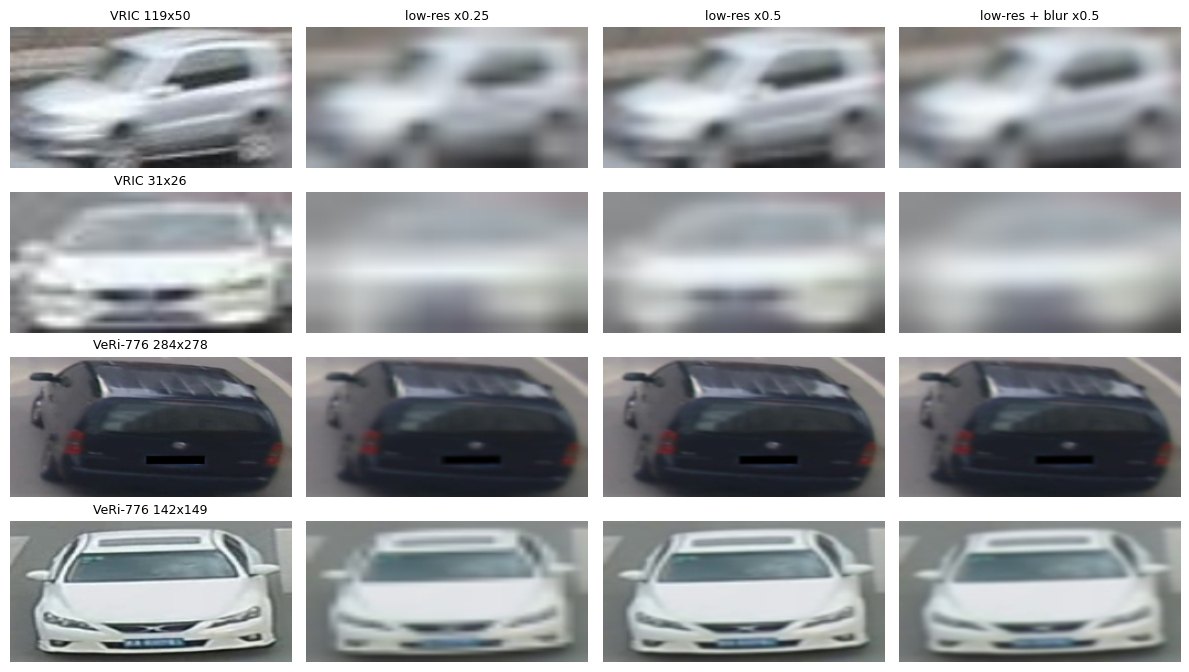

In [102]:
# ===== STEP 3a: the augmentation + a visual check =====
import matplotlib.pyplot as plt

class RandomLowRes:
    """Degrades the image at its NATIVE size, BEFORE torchreid's Resize to (HEIGHT, WIDTH)."""
    def __init__(self, p=0.5, scale=(0.25, 0.75), blur_p=0.0, sigma=(0.5, 1.5)):
        self.p, self.scale, self.blur_p, self.sigma = p, scale, blur_p, sigma
    def __call__(self, img):
        w, h = img.size
        if random.random() < self.p:
            f = random.uniform(*self.scale)
            img = img.resize((max(8, round(w * f)), max(8, round(h * f))), Image.BILINEAR).resize((w, h), Image.BILINEAR)
        if self.blur_p > 0 and random.random() < self.blur_p:
            img = img.filter(ImageFilter.GaussianBlur(radius=random.uniform(*self.sigma)))
        return img
    def __repr__(self):
        return f'RandomLowRes(p={self.p}, scale={self.scale}, blur_p={self.blur_p}, sigma={self.sigma})'

def add_aug(dm, cfg):
    tf = dm.train_loader.dataset.transform
    i = next(i for i, t in enumerate(tf.transforms) if isinstance(t, T.Resize))
    tf.transforms.insert(i, RandomLowRes(**cfg))     # BEFORE Resize
    print('train transforms:', tf)

# visual check on TRAINING images only (never query/test images)
rng_vis = random.Random(0)
samples = [(ds, n) for ds in DATASETS for n, _, _ in rng_vis.sample(SPLITS[ds]['train'], 2)]
forced = [('input', None), ('low-res', RandomLowRes(p=1, scale=(0.25, 0.25))),
          ('low-res', RandomLowRes(p=1, scale=(0.5, 0.5))),
          ('low-res + blur', RandomLowRes(p=1, scale=(0.5, 0.5), blur_p=1, sigma=(1.5, 1.5)))]
fig, axes = plt.subplots(len(samples), len(forced), figsize=(3 * len(forced), 1.7 * len(samples)))
for r, (ds, n) in enumerate(samples):
    img = Image.open(f"{local_dir(ds, 'train')}/{n}").convert('RGB')     # native size
    for c, (title, tfm) in enumerate(forced):
        axes[r, c].imshow(_resize(img if tfm is None else tfm(img))); axes[r, c].axis('off')   # then model-input resize
        label = f"{DATASETS[ds]['name']} {img.size[0]}x{img.size[1]}" if tfm is None else (f'{title} x{tfm.scale[0]}' if r == 0 else '')
        axes[r, c].set_title(label, fontsize=9)
plt.tight_layout(); plt.savefig(f'{RESEARCH_DIR}/augmentation_examples.png', dpi=120); plt.show()

In [103]:
# ===== STEP 3b: train baseline + augmented models on every dataset =====
# Safe to interrupt (stop button / disconnect) at any time: a checkpoint is saved to Drive after every epoch.
# Re-run (or Run All) and finished runs are skipped; an unfinished run resumes from its last saved epoch.
def run_dir(ds, variant, seed): return f'{RESEARCH_DIR}/{ds}/runs/{variant}_s{seed}'
def ckpt_path(ds, variant, seed): return f'{run_dir(ds, variant, seed)}/model/model.pth.tar-{MAX_EPOCH}'

def _saved_epochs(ds, variant, seed):
    d = f'{run_dir(ds, variant, seed)}/model'
    if not osp.isdir(d): return []
    return sorted(int(f.rsplit('-', 1)[1]) for f in os.listdir(d) if re.fullmatch(r'model\.pth\.tar-\d+', f))

def _resume(ds, variant, seed, model, opt, sch):
    """Load the newest readable per-epoch checkpoint (model + optimizer + LR schedule). Returns the epoch to start from."""
    for ep in reversed(_saved_epochs(ds, variant, seed)):
        path = f'{run_dir(ds, variant, seed)}/model/model.pth.tar-{ep}'
        try:
            ck = torch.load(path, map_location='cpu', weights_only=False)
        except Exception as e:                       # e.g. half-written file from a disconnect
            print(f'  checkpoint {path} unreadable ({e}); deleting it'); os.remove(path); continue
        model.load_state_dict(ck['state_dict']); opt.load_state_dict(ck['optimizer']); sch.load_state_dict(ck['scheduler'])
        print(f'  RESUMING from epoch {ck["epoch"]}/{MAX_EPOCH}')
        with open(f'{run_dir(ds, variant, seed)}/resumed.txt', 'a') as f:
            f.write(f'resumed from epoch {ck["epoch"]}\n')
        return ck['epoch']
    return 0

def train_run(ds, variant, seed):
    if osp.exists(ckpt_path(ds, variant, seed)):
        print(f'[skip] {ds} {variant} seed {seed}: finished checkpoint already on Drive'); return
    print(f'\n######## training {DATASETS[ds]["name"]} | {variant} | seed {seed} ########')
    torchreid.utils.set_random_seed(seed)
    dm = torchreid.data.ImageDataManager(root=WORK, sources=f'{ds}_research', height=HEIGHT, width=WIDTH,
                                         batch_size_train=BATCH_TRAIN, batch_size_test=100,
                                         transforms=['random_flip', 'color_jitter'])
    if AUG_VARIANTS[variant] is not None:
        add_aug(dm, AUG_VARIANTS[variant])
    model = torchreid.models.build_model('osnet_x1_0', num_classes=dm.num_train_pids,
                                         loss='softmax', pretrained=True).to(device)
    opt = torchreid.optim.build_optimizer(model, optim='adam', lr=LR)
    sch = torchreid.optim.build_lr_scheduler(opt, lr_scheduler='single_step', stepsize=20)
    start_epoch = _resume(ds, variant, seed, model, opt, sch)
    engine = torchreid.engine.ImageSoftmaxEngine(dm, model, optimizer=opt, scheduler=sch)
    # eval_freq=1 -> torchreid saves model+optimizer+scheduler to Drive after EVERY epoch (with a quick 20-ID progress test)
    engine.run(save_dir=run_dir(ds, variant, seed), max_epoch=MAX_EPOCH, start_epoch=start_epoch,
               eval_freq=1, print_freq=200)
    for ep in _saved_epochs(ds, variant, seed):      # run finished: drop intermediate checkpoints to save Drive space
        if ep != MAX_EPOCH:
            os.remove(f'{run_dir(ds, variant, seed)}/model/model.pth.tar-{ep}')
    del engine, model, opt, sch, dm; torch.cuda.empty_cache()

# seed-major order: if you run out of time you still have every dataset x variant for the first seed(s)
for seed in SEEDS:
    for ds in DATASETS:
        for variant in AUG_VARIANTS:
            train_run(ds, variant, seed)

[skip] vric baseline seed 0: finished checkpoint already on Drive
[skip] vric lowres seed 0: finished checkpoint already on Drive
[skip] vric lowres_blur seed 0: finished checkpoint already on Drive
[skip] veri baseline seed 0: finished checkpoint already on Drive
[skip] veri lowres seed 0: finished checkpoint already on Drive
[skip] veri lowres_blur seed 0: finished checkpoint already on Drive
[skip] vric baseline seed 1: finished checkpoint already on Drive
[skip] vric lowres seed 1: finished checkpoint already on Drive
[skip] vric lowres_blur seed 1: finished checkpoint already on Drive
[skip] veri baseline seed 1: finished checkpoint already on Drive
[skip] veri lowres seed 1: finished checkpoint already on Drive
[skip] veri lowres_blur seed 1: finished checkpoint already on Drive
[skip] vric baseline seed 2: finished checkpoint already on Drive
[skip] vric lowres seed 2: finished checkpoint already on Drive
[skip] vric lowres_blur seed 2: finished checkpoint already on Drive
[skip

In [104]:
# ===== STEP 3c: evaluate every trained model on its full query/gallery (cached) =====
RESULTS = {}
for seed in SEEDS:
    for ds in DATASETS:
        for variant in AUG_VARIANTS:
            if not osp.exists(ckpt_path(ds, variant, seed)):
                print(f'missing: {ds} {variant} seed {seed}'); continue
            RESULTS[(ds, variant, seed)] = eval_full(ds, ckpt_path(ds, variant, seed),
                                                     f'{run_dir(ds, variant, seed)}/full_eval.npz')

# training variance: mAP per seed, then mean +/- std across seeds
AVG = {}
for ds in DATASETS:
    runs = {(v, s): r for (d, v, s), r in RESULTS.items() if d == ds}
    if not runs: continue
    per_seed = pd.DataFrame([{'variant': v, 'seed': s, **{g: 100 * np.nanmean(r['ap'][m]) for g, m in GROUPS[ds].items()}}
                             for (v, s), r in runs.items()])
    per_seed.to_csv(f'{RESEARCH_DIR}/{ds}/per_seed_mAP.csv', index=False)
    agg = per_seed.groupby('variant')[list(GROUPS[ds])].agg(['mean', 'std'])
    print(f"\n===== {DATASETS[ds]['name']}: mAP across seeds (mean +/- std) =====")
    display(pd.DataFrame({g: [f"{agg.loc[v, (g, 'mean')]:.1f} +/- {agg.loc[v, (g, 'std')]:.1f}" for v in agg.index]
                          for g in GROUPS[ds]}, index=agg.index).T)
    AVG[ds] = {v: {k: np.mean(np.stack([r[k] for (vv, s), r in runs.items() if vv == v]), 0) for k in ['ap', 'r1', 'r5']}
               for v in AUG_VARIANTS if any(vv == v for vv, _ in runs)}


===== VRIC: mAP across seeds (mean +/- std) =====


variant,baseline,lowres,lowres_blur
full query,36.7 +/- 0.7,39.3 +/- 0.7,39.0 +/- 0.4
blurry (raw),40.2 +/- 0.9,41.8 +/- 0.8,42.3 +/- 0.5
sharp (raw),33.3 +/- 0.5,36.8 +/- 1.3,35.6 +/- 0.4
low-res,31.6 +/- 0.9,34.8 +/- 0.8,34.5 +/- 0.3
high-res,41.8 +/- 0.6,43.8 +/- 0.6,43.4 +/- 0.6
low-res & blurry,30.8 +/- 0.8,33.5 +/- 0.7,33.1 +/- 0.2
low-res & sharp,35.1 +/- 3.1,40.0 +/- 1.5,40.4 +/- 0.8
high-res & blurry,30.8 +/- 0.3,33.2 +/- 0.7,34.5 +/- 1.2
high-res & sharp,44.6 +/- 0.8,46.5 +/- 0.6,45.7 +/- 0.8



===== VeRi-776: mAP across seeds (mean +/- std) =====


variant,baseline,lowres,lowres_blur
full query,45.7 +/- 0.3,45.3 +/- 0.3,45.0 +/- 0.6
blurry (raw),47.4 +/- 0.4,47.5 +/- 0.2,46.7 +/- 0.9
sharp (raw),43.9 +/- 0.3,43.1 +/- 0.5,43.3 +/- 0.3
low-res,43.7 +/- 0.6,42.9 +/- 0.7,43.0 +/- 0.6
high-res,47.6 +/- 0.4,47.7 +/- 0.4,47.0 +/- 0.5
low-res & blurry,42.3 +/- 0.5,41.7 +/- 0.5,41.8 +/- 0.9
low-res & sharp,46.4 +/- 0.9,45.2 +/- 1.1,45.4 +/- 0.4
high-res & blurry,44.5 +/- 0.5,44.6 +/- 0.3,43.1 +/- 0.9
high-res & sharp,49.2 +/- 0.7,49.4 +/- 0.5,48.9 +/- 0.4


## Steps 4 + 5: uncertainty and summary
CIs come from bootstrapping queries (1,000 resamples), applied to each variant's per-query metrics averaged over seeds. Δ columns are **paired**: same queries, augmented minus baseline. Seed-to-seed spread is shown separately above. The two together cover test-set noise and training noise.

In [105]:
# ===== STEP 4/5: summary tables =====
def summary_table(ds, aug_name):
    base, aug = AVG[ds]['baseline'], AVG[ds][aug_name]
    return pd.DataFrame([{'group': g, 'n': int(m.sum()),
                          'baseline mAP': fmt(boot_ci(base['ap'][m])), f'{aug_name} mAP': fmt(boot_ci(aug['ap'][m])),
                          'Δ mAP': fmt(boot_paired_diff(aug['ap'][m], base['ap'][m])),
                          'baseline R1': fmt(boot_ci(base['r1'][m])), f'{aug_name} R1': fmt(boot_ci(aug['r1'][m])),
                          'Δ R1': fmt(boot_paired_diff(aug['r1'][m], base['r1'][m]))}
                         for g, m in GROUPS[ds].items()])

def gap_change(ds, aug_name, B=N_BOOT, seed=0):
    """(low-res gain) - (high-res gain): positive = augmentation shrinks the low-res gap."""
    lo, base, aug = LO_RES[ds], AVG[ds]['baseline']['ap'], AVG[ds][aug_name]['ap']
    d_lo, d_hi = _clean(aug[lo] - base[lo]), _clean(aug[~lo] - base[~lo])
    rng = np.random.default_rng(seed)
    bs = d_lo[rng.integers(0, len(d_lo), (B, len(d_lo)))].mean(1) - d_hi[rng.integers(0, len(d_hi), (B, len(d_hi)))].mean(1)
    return 100 * (d_lo.mean() - d_hi.mean()), 100 * np.percentile(bs, 2.5), 100 * np.percentile(bs, 97.5)

for ds in AVG:
    name = DATASETS[ds]['name']
    if 'baseline' not in AVG[ds]:
        print(f'{name}: no baseline runs yet'); continue
    n_seeds = {v: sum(1 for (d, vv, s) in RESULTS if d == ds and vv == v) for v in AVG[ds]}
    print(f'\n################ {name} ################   seeds per variant: {n_seeds}')
    for v in AVG[ds]:
        if v == 'baseline': continue
        tag = 'MAIN RESULT (pre-specified primary)' if v == PRIMARY_AUG else 'secondary'
        print(f'\n=== {name} | {tag}: baseline vs. {v} ===')
        t = summary_table(ds, v); t.to_csv(f'{RESEARCH_DIR}/{ds}/summary_{v}.csv', index=False); display(t)
    print(f'\n{name}: low-res gap (high-res mAP - low-res mAP)')
    for v in AVG[ds]:
        print(f'  {v:12s} {fmt(boot_unpaired_diff(AVG[ds][v]["ap"][~LO_RES[ds]], AVG[ds][v]["ap"][LO_RES[ds]]))}')
    for v in AVG[ds]:
        if v != 'baseline':
            print(f'  gap closed by {v} (low-res gain - high-res gain): {fmt(gap_change(ds, v))}')
    print(f'\n{name}: blur effect at fixed resolution, per model')
    display(pd.concat([blur_effect(AVG[ds][v], v, ds) for v in AVG[ds]], ignore_index=True))


################ VRIC ################   seeds per variant: {'baseline': 3, 'lowres': 3, 'lowres_blur': 3}

=== VRIC | MAIN RESULT (pre-specified primary): baseline vs. lowres ===


,group,n,baseline mAP,lowres mAP,Δ mAP,baseline R1,lowres R1,Δ R1
0,full query,2811,"36.7 [35.3, 38.1]","39.3 [37.9, 40.6]","2.6 [1.9, 3.3]","26.9 [25.4, 28.2]","28.9 [27.5, 30.3]","2.0 [1.1, 2.9]"
1,blurry (raw),1405,"40.2 [38.2, 42.2]","41.8 [39.9, 43.8]","1.6 [0.5, 2.5]","30.1 [28.1, 32.2]","31.1 [29.0, 33.1]","0.9 [-0.4, 2.2]"
2,sharp (raw),1406,"33.3 [31.5, 35.0]","36.8 [35.0, 38.7]","3.5 [2.5, 4.6]","23.7 [21.9, 25.5]","26.7 [24.8, 28.6]","3.0 [1.7, 4.3]"
3,low-res,1404,"31.6 [29.8, 33.4]","34.8 [33.0, 36.6]","3.2 [2.1, 4.2]","21.6 [19.8, 23.4]","24.0 [22.1, 25.9]","2.4 [1.0, 3.7]"
4,high-res,1407,"41.8 [39.9, 44.1]","43.8 [41.8, 45.9]","2.0 [1.0, 3.0]","32.2 [30.2, 34.6]","33.7 [31.7, 36.0]","1.5 [0.2, 2.8]"
5,low-res & blurry,1120,"30.8 [28.9, 32.8]","33.5 [31.4, 35.4]","2.7 [1.5, 3.8]","20.5 [18.6, 22.6]","22.6 [20.6, 24.6]","2.1 [0.5, 3.5]"
6,low-res & sharp,284,"35.1 [31.2, 39.2]","40.0 [35.7, 44.4]","4.9 [2.6, 7.5]","25.6 [21.6, 29.7]","29.6 [25.1, 34.2]","4.0 [1.1, 7.2]"
7,high-res & blurry,285,"30.8 [26.7, 34.8]","33.2 [29.1, 37.2]","2.4 [0.5, 4.5]","21.6 [17.7, 25.6]","23.4 [19.2, 27.1]","1.8 [-0.8, 4.3]"
8,high-res & sharp,1122,"44.6 [42.3, 46.7]","46.5 [44.2, 48.8]","1.9 [0.8, 3.0]","34.9 [32.4, 37.2]","36.3 [33.9, 38.8]","1.5 [-0.1, 3.1]"



=== VRIC | secondary: baseline vs. lowres_blur ===


,group,n,baseline mAP,lowres_blur mAP,Δ mAP,baseline R1,lowres_blur R1,Δ R1
0,full query,2811,"36.7 [35.3, 38.1]","39.0 [37.7, 40.4]","2.2 [1.5, 2.9]","26.9 [25.4, 28.2]","28.8 [27.5, 30.3]","2.0 [1.1, 2.8]"
1,blurry (raw),1405,"40.2 [38.2, 42.2]","42.3 [40.3, 44.3]","2.1 [1.1, 3.1]","30.1 [28.1, 32.2]","31.9 [29.8, 34.0]","1.8 [0.4, 3.2]"
2,sharp (raw),1406,"33.3 [31.5, 35.0]","35.6 [33.8, 37.4]","2.4 [1.2, 3.4]","23.7 [21.9, 25.5]","25.8 [23.9, 27.7]","2.1 [0.8, 3.4]"
3,low-res,1404,"31.6 [29.8, 33.4]","34.5 [32.8, 36.4]","2.9 [1.8, 4.0]","21.6 [19.8, 23.4]","24.1 [22.3, 26.0]","2.5 [1.0, 3.8]"
4,high-res,1407,"41.8 [39.9, 44.1]","43.4 [41.3, 45.6]","1.6 [0.5, 2.6]","32.2 [30.2, 34.6]","33.6 [31.4, 35.8]","1.4 [-0.1, 2.8]"
5,low-res & blurry,1120,"30.8 [28.9, 32.8]","33.1 [31.1, 34.9]","2.3 [1.1, 3.3]","20.5 [18.6, 22.6]","22.4 [20.4, 24.2]","1.8 [0.4, 3.2]"
6,low-res & sharp,284,"35.1 [31.2, 39.2]","40.4 [35.9, 44.7]","5.3 [2.8, 8.0]","25.6 [21.6, 29.7]","30.9 [26.6, 35.4]","5.3 [2.1, 8.3]"
7,high-res & blurry,285,"30.8 [26.7, 34.8]","34.5 [30.5, 38.6]","3.7 [1.6, 5.8]","21.6 [17.7, 25.6]","25.0 [20.9, 29.2]","3.4 [0.8, 6.0]"
8,high-res & sharp,1122,"44.6 [42.3, 46.7]","45.7 [43.4, 47.9]","1.0 [-0.0, 2.2]","34.9 [32.4, 37.2]","35.8 [33.4, 38.1]","0.9 [-0.6, 2.4]"



VRIC: low-res gap (high-res mAP - low-res mAP)
  baseline     10.2 [7.5, 13.1]
  lowres       9.0 [6.3, 11.8]
  lowres_blur  8.9 [6.2, 11.6]
  gap closed by lowres (low-res gain - high-res gain): 1.2 [-0.4, 2.6]
  gap closed by lowres_blur (low-res gain - high-res gain): 1.3 [-0.3, 2.8]

VRIC: blur effect at fixed resolution, per model


,dataset,model,within,n sharp / blurry,mAP sharp - blurry [95% CI]
0,VRIC,baseline,low-res,284 / 1120,"4.3 [0.2, 9.0]"
1,VRIC,baseline,high-res,1122 / 285,"13.8 [9.5, 18.3]"
2,VRIC,baseline,all (partial Spearman AP~blur_norm | res),,"rho = +0.056 [+0.019, +0.091]"
3,VRIC,lowres,low-res,284 / 1120,"6.5 [1.8, 11.4]"
4,VRIC,lowres,high-res,1122 / 285,"13.3 [8.9, 18.2]"
5,VRIC,lowres,all (partial Spearman AP~blur_norm | res),,"rho = +0.081 [+0.044, +0.116]"
6,VRIC,lowres_blur,low-res,284 / 1120,"7.3 [2.7, 12.5]"
7,VRIC,lowres_blur,high-res,1122 / 285,"11.2 [6.6, 15.9]"
8,VRIC,lowres_blur,all (partial Spearman AP~blur_norm | res),,"rho = +0.060 [+0.024, +0.096]"


... (2 outputs left out)


=== VeRi-776 | secondary: baseline vs. lowres_blur ===


,group,n,baseline mAP,lowres_blur mAP,Δ mAP,baseline R1,lowres_blur R1,Δ R1
0,full query,1678,"45.7 [44.6, 46.7]","45.0 [43.9, 46.0]","-0.6 [-1.0, -0.3]","84.9 [83.4, 86.3]","83.9 [82.3, 85.3]","-1.1 [-1.9, -0.1]"
1,blurry (raw),839,"47.4 [46.0, 49.0]","46.7 [45.3, 48.3]","-0.7 [-1.2, -0.2]","85.6 [83.5, 87.5]","84.7 [82.5, 86.7]","-0.9 [-2.2, 0.3]"
2,sharp (raw),839,"43.9 [42.5, 45.3]","43.3 [41.8, 44.8]","-0.6 [-1.1, -0.1]","84.3 [82.1, 86.4]","83.1 [80.9, 85.3]","-1.2 [-2.3, 0.0]"
3,low-res,839,"43.7 [42.2, 45.1]","43.0 [41.5, 44.5]","-0.6 [-1.2, -0.1]","83.9 [81.7, 85.9]","82.6 [80.2, 84.8]","-1.3 [-2.5, 0.0]"
4,high-res,839,"47.6 [46.1, 49.0]","47.0 [45.4, 48.3]","-0.7 [-1.2, -0.2]","86.0 [84.0, 87.8]","85.2 [83.1, 87.1]","-0.8 [-2.1, 0.3]"
5,low-res & blurry,556,"42.3 [40.5, 44.2]","41.8 [40.1, 43.7]","-0.5 [-1.1, 0.2]","80.0 [77.1, 82.8]","78.6 [75.4, 81.5]","-1.4 [-3.1, 0.2]"
6,low-res & sharp,283,"46.4 [44.2, 48.6]","45.4 [43.2, 47.8]","-1.0 [-1.8, -0.1]","91.4 [88.5, 94.0]","90.5 [87.5, 93.1]","-0.9 [-2.7, 0.9]"
7,high-res & blurry,283,"44.5 [42.0, 46.9]","43.1 [40.7, 45.3]","-1.4 [-2.3, -0.6]","80.9 [76.8, 84.9]","79.0 [74.7, 82.9]","-1.9 [-4.5, 0.6]"
8,high-res & sharp,556,"49.2 [47.4, 51.0]","48.9 [47.1, 50.8]","-0.3 [-0.9, 0.3]","88.6 [86.2, 90.9]","88.3 [85.9, 90.6]","-0.3 [-1.7, 1.1]"



VeRi-776: low-res gap (high-res mAP - low-res mAP)
  baseline     3.9 [1.8, 5.9]
  lowres       4.9 [2.7, 6.9]
  lowres_blur  3.9 [1.8, 5.9]
  gap closed by lowres (low-res gain - high-res gain): -0.9 [-1.7, -0.2]
  gap closed by lowres_blur (low-res gain - high-res gain): 0.0 [-0.7, 0.7]

VeRi-776: blur effect at fixed resolution, per model


,dataset,model,within,n sharp / blurry,mAP sharp - blurry [95% CI]
0,VeRi-776,baseline,low-res,283 / 556,"4.0 [1.1, 7.1]"
1,VeRi-776,baseline,high-res,556 / 283,"4.7 [1.7, 7.9]"
2,VeRi-776,baseline,all (partial Spearman AP~blur_norm | res),,"rho = +0.096 [+0.043, +0.147]"
3,VeRi-776,lowres,low-res,283 / 556,"3.5 [0.4, 6.5]"
4,VeRi-776,lowres,high-res,556 / 283,"4.8 [1.9, 7.7]"
5,VeRi-776,lowres,all (partial Spearman AP~blur_norm | res),,"rho = +0.069 [+0.016, +0.119]"
6,VeRi-776,lowres_blur,low-res,283 / 556,"3.6 [0.5, 6.5]"
7,VeRi-776,lowres_blur,high-res,556 / 283,"5.8 [2.8, 8.9]"
8,VeRi-776,lowres_blur,all (partial Spearman AP~blur_norm | res),,"rho = +0.092 [+0.040, +0.143]"


In [106]:
# ===== STEP 5: leakage / fairness checks =====
for ds, S in SPLITS.items():
    qn, qp, qc = labels(ds, 'query'); gn, gp, gc = labels(ds, 'gallery')
    train_ids = {p for _, p, _ in S['train']}
    print(f"\n===== {DATASETS[ds]['name']} =====")
    print(f'  train/test identity overlap:      {len(train_ids & set(qp.tolist()) | train_ids & set(gp.tolist()))}  (must be 0)')
    dup = set(qn) & set(gn)
    g_cam_of = dict(zip(gn, gc)); q_cam_of = dict(zip(qn, qc))
    print(f'  query images also in gallery:     {len(dup)}'
          + (f'  (all same camera -> removed by the same-camera filter: {all(g_cam_of[n] == q_cam_of[n] for n in dup)})' if dup else ''))
    print(f'  gallery images per identity:      max {pd.Series(gp).value_counts().max()}'
          + ('  (1 => mAP equals mean reciprocal rank)' if pd.Series(gp).value_counts().max() == 1 else ''))
    same_cam = np.mean([((gp == p) & (gc == c)).sum() / max(1, (gp == p).sum()) for p, c in zip(qp, qc)])
    print(f'  share of true matches dropped as same-camera: {same_cam:.1%}')
    if ds == 'vric':
        video = lambda n: '_'.join(n.split('_')[:2])          # MVI_20011_016_img00105.jpg -> MVI_20011
        gv = {p: video(n) for n, p, _ in S['gallery']}
        print(f'  query and its gallery match from the same UA-DETRAC video: {np.mean([video(n) == gv[p] for n, p, _ in S["query"]]):.1%}')
print('\nquality thresholds come from query image statistics only (no labels or results)')


===== VRIC =====
  train/test identity overlap:      0  (must be 0)
  query images also in gallery:     0
  gallery images per identity:      max 1  (1 => mAP equals mean reciprocal rank)
  share of true matches dropped as same-camera: 0.0%
  query and its gallery match from the same UA-DETRAC video: 100.0%

===== VeRi-776 =====
  train/test identity overlap:      0  (must be 0)
  query images also in gallery:     1678  (all same camera -> removed by the same-camera filter: True)
  gallery images per identity:      max 202
  share of true matches dropped as same-camera: 11.9%

quality thresholds come from query image statistics only (no labels or results)


## Next steps: deployment view (no retraining)
Everything below reuses the cached per-query results and checkpoints on Drive.
- **Quality gate:** route the lowest-quality queries to a human instead of trusting the model, and measure how much that raises mAP on the queries the model keeps.
- **Inference cost:** latency and throughput of the trained model on the Colab T4.
- **Experiment tracking:** log every run (config, full-gallery metrics, training curves) to MLflow.

,dataset,model,gate,defer %,kept,mAP all,mAP kept,gain vs. no gate [95% CI],R1 kept,mAP of deferred,oracle mAP kept
0,VRIC,baseline,quality (res + blur),10,2530,36.7,38.5,"1.8 [1.4, 2.2]",28.5,20.7,40.8
1,VRIC,baseline,resolution only,10,2530,36.7,38.0,"1.2 [0.8, 1.7]",28.0,25.6,40.8
2,VRIC,baseline,quality (res + blur),20,2249,36.7,40.1,"3.3 [2.8, 4.0]",30.0,23.3,45.8
3,VRIC,baseline,resolution only,20,2249,36.7,39.1,"2.4 [1.7, 3.0]",29.3,27.3,45.8
4,VRIC,baseline,quality (res + blur),30,1968,36.7,40.5,"3.7 [2.9, 4.6]",30.5,28.0,51.8
5,VRIC,baseline,resolution only,30,1968,36.7,39.9,"3.2 [2.3, 4.0]",30.0,29.4,51.8
6,VRIC,lowres,quality (res + blur),10,2530,39.3,41.0,"1.6 [1.2, 2.0]",30.4,24.5,43.7
7,VRIC,lowres,resolution only,10,2530,39.3,40.4,"1.1 [0.7, 1.5]",29.9,29.6,43.7
8,VRIC,lowres,quality (res + blur),20,2249,39.3,42.5,"3.2 [2.6, 3.9]",31.9,26.5,48.9
9,VRIC,lowres,resolution only,20,2249,39.3,41.4,"2.0 [1.4, 2.6]",31.0,31.1,48.9


random deferral keeps mAP at "mAP all" on average; a useful gate must beat it (gain CI above 0).


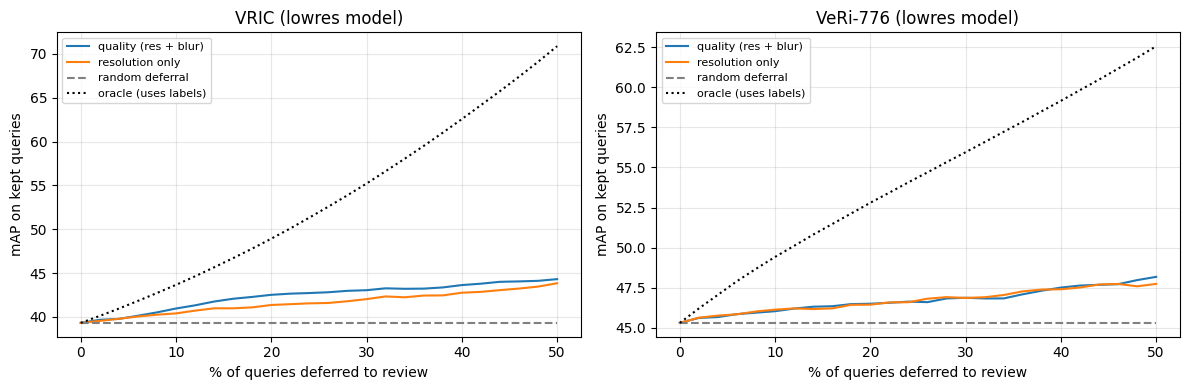

In [107]:
# ===== NEXT STEP A: quality gate (defer the lowest-quality queries to human review) =====
# Gate score, fixed BEFORE looking at results: mean percentile rank of log(resolution) and blur_norm.
# Both come from the query image alone (no labels, no model output), so the gate is usable in production.
# Secondary score: resolution alone. Comparisons:
#   random deferral -> kept mAP = full mAP on average (the "does the gate know anything?" baseline)
#   oracle          -> defers the queries with the LOWEST AP (needs labels; upper bound only)
DEFER = [0.1, 0.2, 0.3]
GATE_SCORES = {
    'quality (res + blur)': lambda ds: (rankdata(np.log(QUAL[ds]['resolution'].values)) + rankdata(QUAL[ds]['blur_norm'].values)) / 2,
    'resolution only':      lambda ds: rankdata(QUAL[ds]['resolution'].values),
}

def keep_mask(score, frac):
    """Keep everything except the lowest `frac` of scores."""
    return rankdata(score, method='ordinal') > round(frac * len(score))

def gate_gain(ap, keep, B=N_BOOT, seed=0):
    """mAP(kept) - mAP(all), bootstrapping queries with the threshold held fixed."""
    ok = ~np.isnan(ap); ap, keep = ap[ok], keep[ok]
    idx = np.random.default_rng(seed).integers(0, len(ap), (B, len(ap)))
    a, k = ap[idx], keep[idx]
    d = (a * k).sum(1) / k.sum(1) - a.mean(1)
    return 100 * (ap[keep].mean() - ap.mean()), 100 * np.percentile(d, 2.5), 100 * np.percentile(d, 97.5)

rows = []
for ds in AVG:
    for v in ['baseline', PRIMARY_AUG]:
        if v not in AVG[ds]: continue
        ap, r1 = AVG[ds][v]['ap'], AVG[ds][v]['r1']
        oracle_score = np.nan_to_num(ap, nan=-1.0)
        for frac in DEFER:
            ok = keep_mask(oracle_score, frac)
            for gname, gfun in GATE_SCORES.items():
                k = keep_mask(gfun(ds), frac)
                rows.append({'dataset': DATASETS[ds]['name'], 'model': v, 'gate': gname, 'defer %': int(100 * frac),
                             'kept': int(k.sum()),
                             'mAP all': f'{100 * np.nanmean(ap):.1f}',
                             'mAP kept': f'{100 * np.nanmean(ap[k]):.1f}',
                             'gain vs. no gate [95% CI]': fmt(gate_gain(ap, k)),
                             'R1 kept': f'{100 * np.nanmean(r1[k]):.1f}',
                             'mAP of deferred': f'{100 * np.nanmean(ap[~k]):.1f}',
                             'oracle mAP kept': f'{100 * np.nanmean(ap[ok]):.1f}'})
GATE_TABLE = pd.DataFrame(rows)
GATE_TABLE.to_csv(f'{RESEARCH_DIR}/quality_gate.csv', index=False)
with pd.option_context('display.max_rows', 200, 'display.width', 250):
    display(GATE_TABLE)
print('random deferral keeps mAP at "mAP all" on average; a useful gate must beat it (gain CI above 0).')

# curve: kept mAP vs. fraction deferred, primary model
fracs = np.linspace(0, 0.5, 26)
fig, axes = plt.subplots(1, len(AVG), figsize=(6 * len(AVG), 4), squeeze=False)
for ax, ds in zip(axes[0], AVG):
    ap = AVG[ds][PRIMARY_AUG]['ap']
    for gname, gfun in GATE_SCORES.items():
        s = gfun(ds)
        ax.plot(100 * fracs, [100 * np.nanmean(ap[keep_mask(s, f)]) for f in fracs], label=gname)
    ax.plot(100 * fracs, [100 * np.nanmean(ap)] * len(fracs), '--', color='gray', label='random deferral')
    os_ = np.nan_to_num(ap, nan=-1.0)
    ax.plot(100 * fracs, [100 * np.nanmean(ap[keep_mask(os_, f)]) for f in fracs], ':', color='black', label='oracle (uses labels)')
    ax.set_title(f"{DATASETS[ds]['name']} ({PRIMARY_AUG} model)"); ax.set_xlabel('% of queries deferred to review')
    ax.set_ylabel('mAP on kept queries'); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{RESEARCH_DIR}/quality_gate.png', dpi=120); plt.show()

In [108]:
# ===== NEXT STEP B: inference cost on the Colab T4 =====
import time, json
SPEED = {}
if device.type != 'cuda':
    print('no GPU in this session: skipping the speed benchmark')
else:
    m = load_model(ckpt_path('veri', PRIMARY_AUG, SEEDS[0]))
    n_params = sum(p.numel() for n, p in m.named_parameters() if not n.startswith('classifier'))

    def _sync_time(fn, iters, warmup=10):
        for _ in range(warmup): fn()
        torch.cuda.synchronize(); t = time.perf_counter()
        for _ in range(iters): fn()
        torch.cuda.synchronize()
        return (time.perf_counter() - t) / iters

    rows = []
    for half in [False, True]:
        for bs in [1, 32, 256]:
            x = torch.randn(bs, 3, HEIGHT, WIDTH, device=device)
            def fwd():
                with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16, enabled=half):
                    m(x)
            sec = _sync_time(fwd, iters=100 if bs < 256 else 20)
            rows.append({'precision': 'fp16' if half else 'fp32', 'batch': bs, 'ms / batch': round(1000 * sec, 2),
                         'ms / image': round(1000 * sec / bs, 3), 'images / s': round(bs / sec)})
    speed_table = pd.DataFrame(rows); display(speed_table)

    # end-to-end on a real gallery: 11,579 VeRi images (already decoded + resized in RAM; JPEG decoding not included)
    gal = get_imgs('veri', 'gallery')
    torch.cuda.synchronize(); t = time.perf_counter(); gf = extract_feats(m, gal); torch.cuda.synchronize()
    gal_sec = time.perf_counter() - t
    # retrieval: rank the whole gallery for one query
    gf_gpu, qf1 = gf.to(device), gf[:1].to(device)
    rank_sec = _sync_time(lambda: torch.cdist(qf1, gf_gpu).argsort(dim=1), iters=200)

    SPEED = {'gpu': torch.cuda.get_device_name(0), 'backbone_params_M': round(n_params / 1e6, 2),
             'fp32_bs1_ms': rows[0]['ms / image'], 'fp32_bs256_img_per_s': rows[2]['images / s'],
             'fp16_bs256_img_per_s': rows[5]['images / s'],
             'gallery_images': len(gal), 'gallery_embed_s': round(gal_sec, 2), 'gallery_img_per_s': round(len(gal) / gal_sec),
             'rank_1_query_vs_gallery_ms': round(1000 * rank_sec, 3)}
    json.dump(SPEED, open(f'{RESEARCH_DIR}/inference_speed.json', 'w'), indent=1)
    print(json.dumps(SPEED, indent=1))
    print(f"\nOSNet x1.0 ({SPEED['backbone_params_M']}M params) on a {SPEED['gpu']}: {SPEED['fp32_bs1_ms']} ms per image at batch 1, "
          f"{SPEED['fp32_bs256_img_per_s']} img/s at batch 256 (fp32), {SPEED['fp16_bs256_img_per_s']} img/s (fp16); "
          f"ranking one query against {len(gal)} gallery images takes {SPEED['rank_1_query_vs_gallery_ms']} ms.")
    del m, gf, gf_gpu; torch.cuda.empty_cache()

,precision,batch,ms / batch,ms / image,images / s
0,fp32,1,13.83,13.834,72
1,fp32,32,52.03,1.626,615
2,fp32,256,424.51,1.658,603
3,fp16,1,20.43,20.434,49
4,fp16,32,27.20,0.850,1177
5,fp16,256,205.79,0.804,1244


{
 "gpu": "Tesla T4",
 "backbone_params_M": 2.17,
 "fp32_bs1_ms": 13.834,
 "fp32_bs256_img_per_s": 603,
 "fp16_bs256_img_per_s": 1244,
 "gallery_images": 11579,
 "gallery_embed_s": 19.6,
 "gallery_img_per_s": 591,
 "rank_1_query_vs_gallery_ms": 0.763
}

OSNet x1.0 (2.17M params) on a Tesla T4: 13.834 ms per image at batch 1, 603 img/s at batch 256 (fp32), 1244 img/s (fp16); ranking one query against 11579 gallery images takes 0.763 ms.


In [109]:
# ===== NEXT STEP C: experiment tracking with MLflow =====
# Logs every finished run AFTER the fact from files already on Drive (no retraining):
#   params  = dataset, augmentation, seed, training config
#   metrics = full-gallery mAP / R1 / R5 for every query group
#   curves  = torchreid's per-iteration training loss / accuracy / LR (from its TensorBoard files, if present)
# The database is rebuilt from scratch each time (re-running never duplicates runs) and copied to Drive as mlflow.db.
# To browse it on your PC: download mlflow.db from Drive, then
#   pip install mlflow
#   mlflow ui --backend-store-uri sqlite:///mlflow.db        -> open http://127.0.0.1:5000
import importlib.util, subprocess, sys, glob, time
if importlib.util.find_spec('mlflow') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'mlflow'])
import mlflow
from mlflow.entities import Metric
from mlflow.tracking import MlflowClient

MLF_DIR = f'{WORK}/mlflow'
shutil.rmtree(MLF_DIR, ignore_errors=True); os.makedirs(MLF_DIR)
mlflow.set_tracking_uri(f'sqlite:///{MLF_DIR}/mlflow.db')
EXP = 'vehicle-reid-research-v2'
mlflow.set_experiment(experiment_id=mlflow.create_experiment(EXP, artifact_location=f'{MLF_DIR}/artifacts'))
client = MlflowClient()
key = lambda s: re.sub(r'[^\w./-]+', '_', s.replace(' & ', ' and ')).strip('_')

def tb_curves(path, max_points=500):
    """Training scalars torchreid wrote with TensorBoard: {tag: [(step, value), ...]} (subsampled)."""
    try:
        from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
    except ImportError:
        return {}
    out = {}
    for f in glob.glob(f'{path}/**/events.out.tfevents*', recursive=True):
        ea = EventAccumulator(f, size_guidance={'scalars': 0}); ea.Reload()
        for tag in ea.Tags()['scalars']:
            if tag.startswith('Train/'):          # skip Test/*: that is the 20-ID progress check, not a real result
                out.setdefault(tag, []).extend((e.step, e.value) for e in ea.Scalars(tag))
    for tag, pts in out.items():
        pts.sort(); out[tag] = pts[::max(1, len(pts) // max_points)]
    return out

n_curves = 0
for (ds, v, s), res in sorted(RESULTS.items()):
    params = {'dataset': DATASETS[ds]['name'], 'augmentation': v, 'seed': s, 'aug_params': str(AUG_VARIANTS[v]),
              'model': 'osnet_x1_0 (ImageNet pretrained)', 'loss': 'softmax', 'optimizer': 'adam', 'lr': LR,
              'epochs': MAX_EPOCH, 'batch_size': BATCH_TRAIN, 'input': f'{HEIGHT}x{WIDTH}',
              'train_ids': len({p for _, p, _ in SPLITS[ds]['train']}), 'train_images': len(SPLITS[ds]['train']),
              'query_images': len(SPLITS[ds]['query']), 'gallery_images': len(SPLITS[ds]['gallery'])}
    final = {f'{m}/{key(g)}': float(100 * np.nanmean(res[k][mask]))
             for g, mask in GROUPS[ds].items() for m, k in [('mAP', 'ap'), ('R1', 'r1'), ('R5', 'r5')]}
    with mlflow.start_run(run_name=f'{ds}-{v}-s{s}') as run:
        mlflow.log_params(params); mlflow.log_metrics(final)
        mlflow.set_tags({'primary_comparison': str(v in ('baseline', PRIMARY_AUG)), 'eval': 'full query vs. full gallery'})
        curves = tb_curves(run_dir(ds, v, s)); n_curves += bool(curves)
        ts = int(time.time() * 1000)
        mets = [Metric(key(tag), float(val), ts, int(step)) for tag, pts in curves.items() for step, val in pts]
        for i in range(0, len(mets), 1000):
            client.log_batch(run.info.run_id, metrics=mets[i:i + 1000])

# one summary run with the deployment numbers
with mlflow.start_run(run_name='deployment-summary'):
    if SPEED: mlflow.log_metrics({k: float(x) for k, x in SPEED.items() if isinstance(x, (int, float))})
    if 'GATE_TABLE' in globals():
        for _, r in GATE_TABLE[GATE_TABLE['model'] == PRIMARY_AUG].iterrows():
            mlflow.log_metric(key(f"gate/{r['dataset']}/{r['gate']}/defer{r['defer %']}/mAP_kept"), float(r['mAP kept']))

shutil.copyfile(f'{MLF_DIR}/mlflow.db', f'{RESEARCH_DIR}/mlflow.db')
print(f'logged {len(RESULTS)} training runs (+1 summary) to MLflow; training curves found for {n_curves} of them.')
print(f'database copied to {RESEARCH_DIR}/mlflow.db')
display(mlflow.search_runs(experiment_names=[EXP])[['tags.mlflow.runName', 'params.dataset', 'params.augmentation',
                                                      'params.seed', 'metrics.mAP/full_query', 'metrics.R1/full_query']]
        .sort_values('tags.mlflow.runName').reset_index(drop=True))

2026/11/08 22:28:11 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/08 22:28:11 INFO mlflow.store.db.utils: Updating database tables


logged 18 training runs (+1 summary) to MLflow; training curves found for 18 of them.
database copied to /content/drive/MyDrive/Colab Schoolwork/CAHSI 2026/logs/research_v2/mlflow.db


,tags.mlflow.runName,params.dataset,params.augmentation,params.seed,metrics.mAP/full_query,metrics.R1/full_query
0,deployment-summary,None,None,None,NaN,NaN
1,veri-baseline-s0,VeRi-776,baseline,0,46.015047,85.756853
2,veri-baseline-s1,VeRi-776,baseline,1,45.507405,84.147795
3,veri-baseline-s2,VeRi-776,baseline,2,45.435633,84.922527
4,veri-lowres-s0,VeRi-776,lowres,0,45.284139,84.147795
5,veri-lowres-s1,VeRi-776,lowres,1,45.639191,84.147795
6,veri-lowres-s2,VeRi-776,lowres,2,44.985395,84.326579
7,veri-lowres_blur-s0,VeRi-776,lowres_blur,0,45.607666,84.147795
8,veri-lowres_blur-s1,VeRi-776,lowres_blur,1,44.467735,83.790226
9,veri-lowres_blur-s2,VeRi-776,lowres_blur,2,44.937569,83.730632


## Notes for the write-up

### Caveats and flags
1. **The old numbers were inflated by a small gallery.** On the old 100-ID test subset, the VRIC model scored 68.3 mAP. Against the full 2,811-image gallery the same model scores **37.5 [35.9, 39.0]**. VeRi drops from 56.5 to 49.5. Report only the full-gallery numbers. The old stratified groups reproduce to within 0.1, so the drop comes from the evaluation, not the model.
2. **"Blur" was mostly measuring image size.** Raw Laplacian variance falls as images get larger: Spearman with resolution is −0.49 on VRIC and −0.57 on VeRi. So the old "blurry" group was mostly *high-res* images, which is why "blurry" seemed to beat "sharp" (41.7 vs. 33.3). After resizing every image to 128×256, sharpness correlates *positively* with resolution (+0.76 VRIC, +0.51 VeRi). The two factors are confounded; neither can be studied alone.
3. **Blur's own effect is small.** With resolution held constant, sharper images do retrieve better, but only slightly: partial Spearman ρ is 0.05–0.10, and the VRIC low-res cell's CI touches 0 for the reference model ([−1.5, 8.8]). Call it "small but real", not "large".
4. **The 2×2 groups are unbalanced.** Because blur and resolution move together, the off-diagonal groups (low-res & sharp, high-res & blurry) have only about 285 queries each, versus about 1,120 on the diagonal. Their CIs are wide.
5. **The augmentation result depends on the dataset.**
   - VRIC: the pre-specified `lowres` augmentation raises mAP by **+2.6 [1.9, 3.3]** (3 seeds, seed std ≤ 0.7).
   - VeRi-776: it slightly *hurts*, −0.3 [−0.7, −0.0]. VeRi images are about 280 px, so training on downscaled copies adds a mismatch rather than fixing one.
6. **The augmentation helps broadly, not specifically on low-res images.** On VRIC the low-res gap shrinks by only 1.2 [−0.4, 2.6], and the CI includes 0. High-res queries gain too. Don't claim it "closes the resolution gap".
7. **`lowres_blur` (secondary) is no better than `lowres`.** On VRIC it's within noise (+2.2 vs. +2.6); on VeRi it's slightly worse (−0.6).
8. **The CIs cover test-set noise only.** They come from bootstrapping queries, using per-query metrics averaged over seeds. Training noise is shown separately as the std across 3 seeds. Three seeds is the minimum.
9. **VeRi CIs are somewhat too narrow.** VeRi has 1,678 queries from about 200 vehicles, so queries are not independent. Resampling queries instead of vehicles underestimates the width. VRIC has one query per vehicle, so this doesn't apply there.
10. **VRIC is same-scene retrieval.** All VRIC queries and their gallery matches come from the same UA-DETRAC video (100%), with one gallery image per ID, so mAP equals mean reciprocal rank. It tests robustness to quality changes within a scene, not cross-scene matching.
11. **No leakage.** Train/test ID overlap is 0 on both datasets. Every VeRi query is also in the test folder, but always from the same camera, so the standard same-camera filter removes all of them; 11.9% of true matches are dropped that way.
12. **The VeRi reference model isn't comparable.** It is a k-fold model trained on 384 IDs, so it's a reference point only. The fair comparison is the 300-ID baseline vs. augmented runs, all trained identically.
13. **This is a small-data regime.** 300 IDs and 5 epochs, with VeRi train accuracy at about 99%. Absolute numbers sit well below published full-dataset results; the conclusions are about *relative* effects.
14. **Many comparisons, one pre-specified test.** 9 groups × 2 variants × 2 datasets means some per-group CIs will exclude 0 by chance. The one pre-specified test is full-query baseline vs. `lowres`. Quality thresholds are median splits of query-image statistics (no labels), fixed before any model was evaluated.
15. **Ignore the per-epoch numbers in the training log.** They come from a 20-ID progress check.

### Resume numbers (fill in the gate and speed numbers from the cells above after Run All)
- Found that evaluating on a 100-identity gallery overstated vehicle re-ID mAP **by about 1.8×** (68.3 → 37.5). Rebuilt evaluation on the full 2,811-image gallery with bootstrap 95% CIs.
- Showed an apparent "blurry images retrieve better" effect was a **resolution confound** (Spearman ρ = −0.49 between raw blur score and image size). Separated the two with size-normalized blur and stratified analysis.
- Evaluated robustness under real-world image degradation: low-resolution training augmentation improved mAP by **+2.6 points (95% CI 1.9–3.3, 3 seeds)** on low-quality traffic footage (VRIC). Also showed it **doesn't transfer** to high-resolution data (VeRi-776, −0.3).
- Quality gate: routing the lowest-quality __% of queries to human review raises mAP on the rest from __ to __ (random deferral: no gain).
- Inference: __ ms per image (batch 1) / __ images/s (batch 256) on a T4; ranking a query against 11.6k gallery images takes __ ms. Tracked 18 training runs in MLflow.